In [ ]:
import os

PROJECT_DIR = "/content/AgenticCloudManagement"

folders = [
    "dataset/raw",
    "dataset/processed",
    "notebooks",
    "models",
    "results/graphs",
    "results/tables",
    "agents",
    "logs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folders created successfully!")
print(PROJECT_DIR)

Project folders created successfully!
/content/AgenticCloudManagement


download ALibaba Dataset

In [ ]:
%cd /content/AgenticCloudManagement/dataset/raw

!wget -c -O machine_usage.tar.gz \
http://aliopentrace.oss-cn-beijing.aliyuncs.com/v2018Traces/machine_usage.tar.gz

!wget -c -O machine_meta.tar.gz \
http://aliopentrace.oss-cn-beijing.aliyuncs.com/v2018Traces/machine_meta.tar.gz

/content/AgenticCloudManagement/dataset/raw
--2026-11-04 05:31:06--  http://aliopentrace.oss-cn-beijing.aliyuncs.com/v2018Traces/machine_usage.tar.gz
Resolving aliopentrace.oss-cn-beijing.aliyuncs.com (aliopentrace.oss-cn-beijing.aliyuncs.com)... 8.141.181.219
Connecting to aliopentrace.oss-cn-beijing.aliyuncs.com (aliopentrace.oss-cn-beijing.aliyuncs.com)|8.141.181.219|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1774523160 (1.7G) [application/gzip]
Saving to: ‘machine_usage.tar.gz’

machine_usage.tar.g 100%[===================>]   1.65G  18.3MB/s    in 81s     

2026-11-04 05:32:27 (21.0 MB/s) - ‘machine_usage.tar.gz’ saved [1774523160/1774523160]

--2026-11-04 05:32:28--  http://aliopentrace.oss-cn-beijing.aliyuncs.com/v2018Traces/machine_meta.tar.gz
Resolving aliopentrace.oss-cn-beijing.aliyuncs.com (aliopentrace.oss-cn-beijing.aliyuncs.com)... 8.141.181.219
Connecting to aliopentrace.oss-cn-beijing.aliyuncs.com (aliopentrace.oss-cn-beijing.aliyuncs.com)

In [ ]:
%cd /content/AgenticCloudManagement/dataset/raw

!sha256sum machine_usage.tar.gz
!sha256sum machine_meta.tar.gz

/content/AgenticCloudManagement/dataset/raw
3e6ee87fd204bb85b9e234c5c75a5096580fdabc8f085b224033080090753a7a  machine_usage.tar.gz
b5b1b786b22cd413a3674b8f2ebfb2f02fac991c95df537f363ef2797c8f6d55  machine_meta.tar.gz


inspect the CSV Structure

In [ ]:
import pandas as pd
import os

base_path = "/content/AgenticCloudManagement/dataset/raw"

usage_path = os.path.join(base_path, "machine_usage.csv")
meta_path = os.path.join(base_path, "machine_meta.csv")

# Read only the first 10 rows
usage_sample = pd.read_csv(usage_path, nrows=10)
meta_sample = pd.read_csv(meta_path, nrows=10)

print("MACHINE USAGE COLUMNS:")
print(usage_sample.columns.tolist())

print("\nMACHINE USAGE SAMPLE:")
display(usage_sample)

print("\nMACHINE METADATA COLUMNS:")
print(meta_sample.columns.tolist())

print("\nMACHINE METADATA SAMPLE:")
display(meta_sample)

MACHINE USAGE COLUMNS:
['m_1932', '386640', '41', '92', 'Unnamed: 4', 'Unnamed: 5', '43.04', '33.08', '5']

MACHINE USAGE SAMPLE:


,m_1932,386640,41,92,Unnamed: 4,Unnamed: 5,43.04,33.08,5
0,m_1932,386670,43,92,NaN,NaN,43.04,33.08,5
1,m_1932,386690,44,92,NaN,NaN,43.05,33.08,5
2,m_1932,386800,46,92,NaN,NaN,43.05,33.08,3
3,m_1932,386930,44,93,NaN,NaN,43.05,33.09,4
4,m_1932,387000,41,93,NaN,NaN,43.05,33.09,4
5,m_1932,387090,46,93,NaN,NaN,43.05,33.09,3
6,m_1932,387170,47,93,NaN,NaN,43.05,33.09,4
7,m_1932,387180,46,93,NaN,NaN,43.05,33.09,3
8,m_1932,387200,46,93,NaN,NaN,43.05,33.09,3
9,m_1932,387530,46,93,NaN,NaN,43.06,33.10,5



MACHINE METADATA COLUMNS:
['m_1', '0', '219', '17', '96', '100', 'USING']

MACHINE METADATA SAMPLE:


,m_1,0,219,17,96,100,USING
0,m_1,148984,219,17,96,100,USING
1,m_1,535156,219,17,96,100,USING
2,m_1,552384,219,17,96,100,USING
3,m_1,658423,219,17,96,100,USING
4,m_1,664518,219,17,96,100,USING
5,m_1,681229,219,17,96,100,USING
6,m_1,683653,219,17,96,100,USING
7,m_10,0,128,17,96,100,USING
8,m_10,570024,128,17,96,100,USING
9,m_10,573570,128,17,96,100,USING


In [ ]:
print("Usage dataset:")
print("File size:", round(os.path.getsize(usage_path) / (1024**3), 2), "GB")
print("Columns:", len(usage_sample.columns))

print("\nMetadata dataset:")
print("File size:", round(os.path.getsize(meta_path) / (1024**2), 2), "MB")
print("Columns:", len(meta_sample.columns))

Usage dataset:
File size: 8.38 GB
Columns: 9

Metadata dataset:
File size: 0.53 MB
Columns: 7


In [ ]:
import pandas as pd
import os

base_path = "/content/AgenticCloudManagement/dataset/raw"

usage_columns = [
    "machine_id", "time_stamp",
    "cpu_util_percent", "mem_util_percent",
    "mem_gps", "mkpi", "net_in",
    "net_out", "disk_io_percent"
]

meta_columns = [
    "machine_id", "time_stamp",
    "failure_domain_1", "failure_domain_2",
    "cpu_num", "mem_size", "status"
]

# Read a sample without treating the first record as headers
usage = pd.read_csv(
    f"{base_path}/machine_usage.csv",
    header=None,
    names=usage_columns,
    nrows=20000
)

metadata = pd.read_csv(
    f"{base_path}/machine_meta.csv",
    header=None,
    names=meta_columns,
    nrows=20000
)

print("MACHINE USAGE SAMPLE")
display(usage.head(10))

print("\nDATA TYPES")
print(usage.dtypes)

print("\nMISSING VALUES")
print(usage.isnull().sum())

print("\nCPU STATISTICS")
print(usage["cpu_util_percent"].describe())

print("\nMEMORY STATISTICS")
print(usage["mem_util_percent"].describe())

print("\nUNIQUE MACHINES IN SAMPLE")
print(usage["machine_id"].nunique())

print("\nTIMESTAMP RANGE IN SAMPLE")
print(usage["time_stamp"].min(), "to", usage["time_stamp"].max())

print("\nMETADATA SAMPLE")
display(metadata.head(10))

MACHINE USAGE SAMPLE


,machine_id,time_stamp,cpu_util_percent,mem_util_percent,mem_gps,mkpi,net_in,net_out,disk_io_percent
0,m_1932,386640,41,92,NaN,NaN,43.04,33.08,5
1,m_1932,386670,43,92,NaN,NaN,43.04,33.08,5
2,m_1932,386690,44,92,NaN,NaN,43.05,33.08,5
3,m_1932,386800,46,92,NaN,NaN,43.05,33.08,3
4,m_1932,386930,44,93,NaN,NaN,43.05,33.09,4
5,m_1932,387000,41,93,NaN,NaN,43.05,33.09,4
6,m_1932,387090,46,93,NaN,NaN,43.05,33.09,3
7,m_1932,387170,47,93,NaN,NaN,43.05,33.09,4
8,m_1932,387180,46,93,NaN,NaN,43.05,33.09,3
9,m_1932,387200,46,93,NaN,NaN,43.05,33.09,3



DATA TYPES
machine_id           object
time_stamp            int64
cpu_util_percent      int64
mem_util_percent      int64
mem_gps             float64
mkpi                float64
net_in              float64
net_out             float64
disk_io_percent       int64
dtype: object

MISSING VALUES
machine_id              0
time_stamp              0
cpu_util_percent        0
mem_util_percent        0
mem_gps             15695
mkpi                15695
net_in                  0
net_out                 0
disk_io_percent         0
dtype: int64

CPU STATISTICS
count    20000.000000
mean        28.575500
std         20.499034
min          3.000000
25%          6.000000
50%         30.000000
75%         43.000000
max         93.000000
Name: cpu_util_percent, dtype: float64

MEMORY STATISTICS
count    20000.000000
mean        91.114900
std          4.577308
min         52.000000
25%         90.000000
50%         92.000000
75%         93.000000
max         98.000000
Name: mem_util_percent, dtype: fl

,machine_id,time_stamp,failure_domain_1,failure_domain_2,cpu_num,mem_size,status
0,m_1,0,219,17.0,96,100,USING
1,m_1,148984,219,17.0,96,100,USING
2,m_1,535156,219,17.0,96,100,USING
3,m_1,552384,219,17.0,96,100,USING
4,m_1,658423,219,17.0,96,100,USING
5,m_1,664518,219,17.0,96,100,USING
6,m_1,681229,219,17.0,96,100,USING
7,m_1,683653,219,17.0,96,100,USING
8,m_10,0,128,17.0,96,100,USING
9,m_10,570024,128,17.0,96,100,USING


In [ ]:
sample = usage[["machine_id", "time_stamp"]].copy()

sample = sample.sort_values(
    ["machine_id", "time_stamp"]
)

sample["time_difference"] = (
    sample.groupby("machine_id")["time_stamp"].diff()
)

print("Timestamp interval distribution:")
print(sample["time_difference"].describe())

print("\nMost common intervals:")
print(sample["time_difference"].value_counts().head(10))

Timestamp interval distribution:
count    19996.000000
mean        99.018304
std        314.095806
min         10.000000
25%         30.000000
50%         60.000000
75%        120.000000
max      23080.000000
Name: time_difference, dtype: float64

Most common intervals:
time_difference
10.0     2231
20.0     1900
30.0     1833
40.0     1559
50.0     1328
60.0     1277
70.0     1126
80.0      909
90.0      868
100.0     759
Name: count, dtype: int64


find the number of machines in the dataset

In [ ]:
import pandas as pd

usage_path = "/content/AgenticCloudManagement/dataset/raw/machine_usage.csv"

columns = [
    "machine_id", "time_stamp",
    "cpu_util_percent", "mem_util_percent",
    "mem_gps", "mkpi", "net_in",
    "net_out", "disk_io_percent"
]

unique_machines = set()
total_rows = 0

for chunk in pd.read_csv(
    usage_path,
    header=None,
    names=columns,
    chunksize=500000
):
    total_rows += len(chunk)
    unique_machines.update(chunk["machine_id"].unique())

print("Total observations:", total_rows)
print("Total unique machines:", len(unique_machines))
print("First 20 machine IDs:", list(sorted(unique_machines))[:20])

Total observations: 246934820
Total unique machines: 4023
First 20 machine IDs: ['m_1', 'm_10', 'm_100', 'm_1000', 'm_1001', 'm_1002', 'm_1003', 'm_1004', 'm_1005', 'm_1006', 'm_1007', 'm_1008', 'm_1009', 'm_101', 'm_1010', 'm_1011', 'm_1012', 'm_1013', 'm_1014', 'm_1015']


Finding the machines with the most observations

In [ ]:
machine_counts = {}

for chunk in pd.read_csv(
    usage_path,
    header=None,
    names=columns,
    usecols=["machine_id"],
    chunksize=500000
):
    counts = chunk["machine_id"].value_counts()

    for machine_id, count in counts.items():
        machine_counts[machine_id] = (
            machine_counts.get(machine_id, 0) + count
        )

machine_counts_df = pd.Series(
    machine_counts,
    name="observation_count"
).sort_values(ascending=False)

print(machine_counts_df.head(20))

m_3330    65044
m_694     65042
m_2967    64788
m_2773    64699
m_103     64676
m_639     64659
m_2014    64627
m_3244    64589
m_1508    64567
m_2366    64530
m_1223    64433
m_2165    64380
m_200     64357
m_132     64340
m_3328    64318
m_2022    64298
m_2148    64291
m_1863    64286
m_2274    64282
m_1732    64264
Name: observation_count, dtype: int64


Examine observation distribution across all machines

In [ ]:
import pandas as pd

counts = pd.Series(machine_counts, name="observations")

print("Machine observation distribution:")
print(counts.describe(percentiles=[
    0.10, 0.25, 0.50, 0.75, 0.90, 0.95
]))

print("\nMachines with fewer than 10,000 observations:",
      (counts < 10000).sum())

print("Machines with more than 40,000 observations:",
      (counts > 40000).sum())

print("\nTop 20 machines:")
display(counts.sort_values(ascending=False).head(20).to_frame())

Machine observation distribution:
count     4023.000000
mean     61380.765598
std       2457.031947
min       3570.000000
10%      59852.200000
25%      60695.000000
50%      61561.000000
75%      62395.500000
90%      63077.800000
95%      63426.900000
max      65044.000000
Name: observations, dtype: float64

Machines with fewer than 10,000 observations: 3
Machines with more than 40,000 observations: 4013

Top 20 machines:


,observations
m_3330,65044
m_694,65042
m_2967,64788
m_2773,64699
m_103,64676
m_639,64659
m_2014,64627
m_3244,64589
m_1508,64567
m_2366,64530


Check timestamp coverage for selected machines

In [ ]:
import pandas as pd

usage_path = (
    "/content/AgenticCloudManagement/dataset/raw/machine_usage.csv"
)

columns = [
    "machine_id", "time_stamp",
    "cpu_util_percent", "mem_util_percent",
    "mem_gps", "mkpi", "net_in",
    "net_out", "disk_io_percent"
]

selected_machines = counts.sort_values(
    ascending=False
).head(5).index.tolist()

print("Selected machines:", selected_machines)

machine_summaries = []

for chunk in pd.read_csv(
    usage_path,
    header=None,
    names=columns,
    chunksize=500000
):
    part = chunk[chunk["machine_id"].isin(selected_machines)]

    if not part.empty:
        machine_summaries.append(
            part[["machine_id", "time_stamp"]]
        )

selected_data = pd.concat(machine_summaries, ignore_index=True)

selected_data = selected_data.sort_values(
    ["machine_id", "time_stamp"]
)

selected_data["gap_seconds"] = (
    selected_data.groupby("machine_id")["time_stamp"].diff()
)

summary = selected_data.groupby("machine_id").agg(
    observations=("time_stamp", "count"),
    start_time=("time_stamp", "min"),
    end_time=("time_stamp", "max"),
    median_gap=("gap_seconds", "median"),
    maximum_gap=("gap_seconds", "max")
)

display(summary)

Selected machines: ['m_3330', 'm_694', 'm_2967', 'm_2773', 'm_103']


,observations,start_time,end_time,median_gap,maximum_gap
machine_id,,,,,
m_103,64676,0,691190,10.0,21670.0
m_2773,64699,770,691190,10.0,19630.0
m_2967,64788,10,691190,10.0,19100.0
m_3330,65044,0,691190,10.0,19750.0
m_694,65042,0,691190,10.0,20150.0


In [ ]:
import pandas as pd
import os

usage_path = (
    "/content/AgenticCloudManagement/dataset/raw/machine_usage.csv"
)

processed_dir = (
    "/content/AgenticCloudManagement/dataset/processed"
)

os.makedirs(processed_dir, exist_ok=True)

columns = [
    "machine_id",
    "time_stamp",
    "cpu_util_percent",
    "mem_util_percent",
    "mem_gps",
    "mkpi",
    "net_in",
    "net_out",
    "disk_io_percent"
]

# Select the 20 machines with the most observations
selected_machines = (
    counts.sort_values(ascending=False)
    .head(20)
    .index.tolist()
)

print("Selected machines:")
print(selected_machines)

selected_chunks = []

for chunk in pd.read_csv(
    usage_path,
    header=None,
    names=columns,
    chunksize=500000
):
    filtered = chunk[
        chunk["machine_id"].isin(selected_machines)
    ]

    if not filtered.empty:
        selected_chunks.append(filtered)

selected_data = pd.concat(
    selected_chunks,
    ignore_index=True
)

selected_data = selected_data.sort_values(
    ["machine_id", "time_stamp"]
).reset_index(drop=True)

output_path = os.path.join(
    processed_dir,
    "selected_machine_usage.csv"
)

selected_data.to_csv(output_path, index=False)

print("\nExtraction completed!")
print("Total observations:", len(selected_data))
print("Unique machines:", selected_data["machine_id"].nunique())
print("Saved:", output_path)

Selected machines:
['m_3330', 'm_694', 'm_2967', 'm_2773', 'm_103', 'm_639', 'm_2014', 'm_3244', 'm_1508', 'm_2366', 'm_1223', 'm_2165', 'm_200', 'm_132', 'm_3328', 'm_2022', 'm_2148', 'm_1863', 'm_2274', 'm_1732']

Extraction completed!
Total observations: 1290470
Unique machines: 20
Saved: /content/AgenticCloudManagement/dataset/processed/selected_machine_usage.csv


In [ ]:
print("Dataset shape:", selected_data.shape)

print("\nMissing values:")
print(selected_data.isnull().sum())

print("\nDuplicate records:")
print(selected_data.duplicated(
    subset=["machine_id", "time_stamp"]
).sum())

print("\nCPU statistics:")
print(selected_data["cpu_util_percent"].describe())

print("\nMemory statistics:")
print(selected_data["mem_util_percent"].describe())

print("\nRecords per machine:")
print(selected_data.groupby("machine_id").size())

Dataset shape: (1290470, 9)

Missing values:
machine_id                0
time_stamp                0
cpu_util_percent          0
mem_util_percent          0
mem_gps             1029809
mkpi                1029809
net_in                    0
net_out                   0
disk_io_percent           0
dtype: int64

Duplicate records:
0

CPU statistics:
count    1.290470e+06
mean     3.894711e+01
std      1.354874e+01
min      3.000000e+00
25%      2.900000e+01
50%      3.700000e+01
75%      4.700000e+01
max      9.800000e+01
Name: cpu_util_percent, dtype: float64

Memory statistics:
count    1.290470e+06
mean     9.065640e+01
std      4.251325e+00
min      5.800000e+01
25%      8.800000e+01
50%      9.100000e+01
75%      9.400000e+01
max      9.800000e+01
Name: mem_util_percent, dtype: float64

Records per machine:
machine_id
m_103     64676
m_1223    64433
m_132     64340
m_1508    64567
m_1732    64264
m_1863    64286
m_200     64357
m_2014    64627
m_2022    64298
m_2148    64291
m_2165  

orecasting features

In [ ]:
import pandas as pd
import numpy as np
import os

input_path = (
    "/content/AgenticCloudManagement/dataset/processed/"
    "selected_machine_usage.csv"
)

output_path = (
    "/content/AgenticCloudManagement/dataset/processed/"
    "forecasting_dataset.csv"
)

df = pd.read_csv(input_path)

df = df.sort_values(
    ["machine_id", "time_stamp"]
).reset_index(drop=True)

# Time difference between observations
df["time_gap"] = (
    df.groupby("machine_id")["time_stamp"].diff()
)

# Previous three CPU and memory observations
for lag in [1, 2, 3]:
    df[f"cpu_lag_{lag}"] = (
        df.groupby("machine_id")["cpu_util_percent"].shift(lag)
    )
    df[f"mem_lag_{lag}"] = (
        df.groupby("machine_id")["mem_util_percent"].shift(lag)
    )

# Next recorded CPU and memory values
df["cpu_target"] = (
    df.groupby("machine_id")["cpu_util_percent"].shift(-1)
)
df["mem_target"] = (
    df.groupby("machine_id")["mem_util_percent"].shift(-1)
)

# Remove rows without complete historical inputs or targets
forecast_df = df.dropna(
    subset=[
        "cpu_lag_1", "cpu_lag_2", "cpu_lag_3",
        "mem_lag_1", "mem_lag_2", "mem_lag_3",
        "cpu_target", "mem_target", "time_gap"
    ]
).copy()

forecast_df.to_csv(output_path, index=False)

print("Forecasting dataset created!")
print("Shape:", forecast_df.shape)
print("Machines:", forecast_df["machine_id"].nunique())
print("Saved:", output_path)

display(forecast_df.head())

Forecasting dataset created!
Shape: (1290390, 18)
Machines: 20
Saved: /content/AgenticCloudManagement/dataset/processed/forecasting_dataset.csv


,machine_id,time_stamp,cpu_util_percent,mem_util_percent,mem_gps,mkpi,net_in,net_out,disk_io_percent,time_gap,cpu_lag_1,mem_lag_1,cpu_lag_2,mem_lag_2,cpu_lag_3,mem_lag_3,cpu_target,mem_target
3,m_103,40,9.0,84,NaN,NaN,33.78,24.41,1,10.0,8.0,84.0,10.0,85.0,8.0,85.0,11.0,85.0
4,m_103,50,11.0,85,NaN,NaN,33.78,24.41,1,10.0,9.0,84.0,8.0,84.0,10.0,85.0,9.0,85.0
5,m_103,60,9.0,85,NaN,NaN,33.78,24.41,1,10.0,11.0,85.0,9.0,84.0,8.0,84.0,9.0,85.0
6,m_103,70,9.0,85,NaN,NaN,33.78,24.41,1,10.0,9.0,85.0,11.0,85.0,9.0,84.0,9.0,84.0
7,m_103,80,9.0,84,NaN,NaN,33.78,24.41,1,10.0,9.0,85.0,9.0,85.0,11.0,85.0,7.0,84.0


Validate forecasting data

In [ ]:
print("Missing values:")
print(forecast_df.isnull().sum())

print("\nCPU target statistics:")
print(forecast_df["cpu_target"].describe())

print("\nMemory target statistics:")
print(forecast_df["mem_target"].describe())

print("\nTime-gap statistics:")
print(forecast_df["time_gap"].describe())

Missing values:
machine_id                0
time_stamp                0
cpu_util_percent          0
mem_util_percent          0
mem_gps             1029748
mkpi                1029748
net_in                    0
net_out                   0
disk_io_percent           0
time_gap                  0
cpu_lag_1                 0
mem_lag_1                 0
cpu_lag_2                 0
mem_lag_2                 0
cpu_lag_3                 0
mem_lag_3                 0
cpu_target                0
mem_target                0
dtype: int64

CPU target statistics:
count    1.290390e+06
mean     3.894813e+01
std      1.354834e+01
min      3.000000e+00
25%      2.900000e+01
50%      3.700000e+01
75%      4.700000e+01
max      9.800000e+01
Name: cpu_target, dtype: float64

Memory target statistics:
count    1.290390e+06
mean     9.065650e+01
std      4.251348e+00
min      5.800000e+01
25%      8.800000e+01
50%      9.100000e+01
75%      9.400000e+01
max      9.800000e+01
Name: mem_target, dtype: float6

Prepare the final forecasting dataset

In [ ]:
import pandas as pd
import os

input_path = (
    "/content/AgenticCloudManagement/dataset/processed/"
    "forecasting_dataset.csv"
)

output_path = (
    "/content/AgenticCloudManagement/dataset/processed/"
    "final_forecasting_dataset.csv"
)

df = pd.read_csv(input_path)

print("Original samples:", len(df))

# Retain observations with a gap of at most 60 seconds
df = df[df["time_gap"] <= 60].copy()

# Select the forecasting features
feature_columns = [
    "cpu_lag_1",
    "cpu_lag_2",
    "cpu_lag_3",
    "mem_lag_1",
    "mem_lag_2",
    "mem_lag_3",
    "time_gap"
]

target_columns = [
    "cpu_target",
    "mem_target"
]

final_df = df[
    [
        "machine_id",
        "time_stamp",
        "time_gap"
    ] + feature_columns + target_columns
].copy()

final_df.to_csv(output_path, index=False)

print("Filtered samples:", len(final_df))
print("Removed samples:", 1290390 - len(final_df))
print("Unique machines:", final_df["machine_id"].nunique())
print("Saved:", output_path)

display(final_df.head())

Original samples: 1290390
Filtered samples: 1289079
Removed samples: 1311
Unique machines: 20
Saved: /content/AgenticCloudManagement/dataset/processed/final_forecasting_dataset.csv


,machine_id,time_stamp,time_gap,cpu_lag_1,cpu_lag_2,cpu_lag_3,mem_lag_1,mem_lag_2,mem_lag_3,time_gap,cpu_target,mem_target
0,m_103,40,10.0,8.0,10.0,8.0,84.0,85.0,85.0,10.0,11.0,85.0
1,m_103,50,10.0,9.0,8.0,10.0,84.0,84.0,85.0,10.0,9.0,85.0
2,m_103,60,10.0,11.0,9.0,8.0,85.0,84.0,84.0,10.0,9.0,85.0
3,m_103,70,10.0,9.0,11.0,9.0,85.0,85.0,84.0,10.0,9.0,84.0
4,m_103,80,10.0,9.0,9.0,11.0,85.0,85.0,85.0,10.0,7.0,84.0


Split training and testing data

In [ ]:
import numpy as np

train_parts = []
test_parts = []

for machine_id, group in final_df.groupby("machine_id"):

    group = group.sort_values("time_stamp")

    split_index = int(len(group) * 0.80)

    train_parts.append(group.iloc[:split_index])
    test_parts.append(group.iloc[split_index:])

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("Training machines:", train_df["machine_id"].nunique())
print("Testing machines:", test_df["machine_id"].nunique())

Training samples: 1031256
Testing samples: 257823
Training machines: 20
Testing machines: 20


filtered using the time gap between the previous and current observation. But we also need to check the gap between the current observation and the target observation.Otherwise  model might be evaluated on a prediction several hours into the future, even though we intended a maximum 60-second forecasting horizon.

Rebuild the final forecasting dataset

In [ ]:
import pandas as pd
import os

base = "/content/AgenticCloudManagement/dataset/processed"

df = pd.read_csv(
    f"{base}/selected_machine_usage.csv"
)

df = df.sort_values(
    ["machine_id", "time_stamp"]
).reset_index(drop=True)

# Historical observation gap
df["input_gap"] = (
    df.groupby("machine_id")["time_stamp"].diff()
)

# Historical CPU and memory features
for lag in [1, 2, 3]:
    df[f"cpu_lag_{lag}"] = (
        df.groupby("machine_id")["cpu_util_percent"].shift(lag)
    )
    df[f"mem_lag_{lag}"] = (
        df.groupby("machine_id")["mem_util_percent"].shift(lag)
    )

# Next recorded values
df["cpu_target"] = (
    df.groupby("machine_id")["cpu_util_percent"].shift(-1)
)
df["mem_target"] = (
    df.groupby("machine_id")["mem_util_percent"].shift(-1)
)

# Time gap to the target observation
df["target_gap"] = (
    df.groupby("machine_id")["time_stamp"].shift(-1)
    - df["time_stamp"]
)

# Keep only short-horizon observations
df = df[
    (df["input_gap"] > 0) &
    (df["input_gap"] <= 60) &
    (df["target_gap"] > 0) &
    (df["target_gap"] <= 60)
].copy()

feature_columns = [
    "cpu_lag_1", "cpu_lag_2", "cpu_lag_3",
    "mem_lag_1", "mem_lag_2", "mem_lag_3",
    "input_gap"
]

target_columns = ["cpu_target", "mem_target"]

final_df = df[
    ["machine_id", "time_stamp", "input_gap", "target_gap"]
    + feature_columns + target_columns
].copy()

final_df.to_csv(
    f"{base}/final_forecasting_dataset.csv",
    index=False
)

print("Final dataset shape:", final_df.shape)
print("Machines:", final_df["machine_id"].nunique())
print("\nInput gap:")
print(final_df["input_gap"].describe())
print("\nTarget gap:")
print(final_df["target_gap"].describe())

Final dataset shape: (1287817, 13)
Machines: 20

Input gap:
          input_gap     input_gap
count  1.287817e+06  1.287817e+06
mean   1.004434e+01  1.004434e+01
std    7.571470e-01  7.571470e-01
min    1.000000e+01  1.000000e+01
25%    1.000000e+01  1.000000e+01
50%    1.000000e+01  1.000000e+01
75%    1.000000e+01  1.000000e+01
max    6.000000e+01  6.000000e+01

Target gap:
count    1.287817e+06
mean     1.004464e+01
std      7.588195e-01
min      1.000000e+01
25%      1.000000e+01
50%      1.000000e+01
75%      1.000000e+01
max      6.000000e+01
Name: target_gap, dtype: float64


Create chronological training and testing sets

In [ ]:
train_parts = []
test_parts = []

for machine_id, group in final_df.groupby("machine_id"):

    group = group.sort_values("time_stamp")

    split_index = int(len(group) * 0.80)

    train_parts.append(group.iloc[:split_index])
    test_parts.append(group.iloc[split_index:])

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("Training machines:", train_df["machine_id"].nunique())
print("Testing machines:", test_df["machine_id"].nunique())

Training samples: 1030246
Testing samples: 257571
Training machines: 20
Testing machines: 20


Training Random Forest models

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib
import os
import time

BASE = "/content/AgenticCloudManagement"

features = [
    "cpu_lag_1",
    "cpu_lag_2",
    "cpu_lag_3",
    "mem_lag_1",
    "mem_lag_2",
    "mem_lag_3",
    "input_gap"
]

# Prepare training and testing features
X_train = train_df[features]
X_test = test_df[features]

y_cpu_train = train_df["cpu_target"]
y_cpu_test = test_df["cpu_target"]

y_mem_train = train_df["mem_target"]
y_mem_test = test_df["mem_target"]

# Random Forest configuration
rf_params = {
    "n_estimators": 100,
    "max_depth": 15,
    "min_samples_leaf": 2,
    "max_features": 1.0,
    "n_jobs": -1,
    "random_state": 42
}

# Train CPU model
start = time.time()

cpu_model = RandomForestRegressor(**rf_params)
cpu_model.fit(X_train, y_cpu_train)

cpu_train_time = time.time() - start

# Train memory model
start = time.time()

mem_model = RandomForestRegressor(**rf_params)
mem_model.fit(X_train, y_mem_train)

mem_train_time = time.time() - start

# Predictions
cpu_rf_pred = cpu_model.predict(X_test)
mem_rf_pred = mem_model.predict(X_test)

print("CPU training time:", round(cpu_train_time, 2), "seconds")
print("Memory training time:", round(mem_train_time, 2), "seconds")

# Save models
os.makedirs(f"{BASE}/models", exist_ok=True)

joblib.dump(cpu_model, f"{BASE}/models/cpu_random_forest.pkl")
joblib.dump(mem_model, f"{BASE}/models/memory_random_forest.pkl")

print("Both Random Forest models saved successfully!")

CPU training time: 340.75 seconds
Memory training time: 285.42 seconds
Both Random Forest models saved successfully!


Implementing of Naïve Persistence baseline

In [ ]:
# Naive Persistence predictions
cpu_persistence_pred = test_df["cpu_lag_1"].to_numpy()
mem_persistence_pred = test_df["mem_lag_1"].to_numpy()

print("Naive Persistence predictions generated!")

Naive Persistence predictions generated!


Compare both models

In [ ]:
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

results = []

for target, actual, rf_pred, persistence_pred in [
    ("CPU", y_cpu_test, cpu_rf_pred, cpu_persistence_pred),
    ("Memory", y_mem_test, mem_rf_pred, mem_persistence_pred)
]:
    rf_mae, rf_rmse = evaluate_model(actual, rf_pred)

    p_mae, p_rmse = evaluate_model(
        actual, persistence_pred
    )

    results.extend([
        {
            "Resource": target,
            "Model": "Random Forest",
            "MAE": rf_mae,
            "RMSE": rf_rmse
        },
        {
            "Resource": target,
            "Model": "Naive Persistence",
            "MAE": p_mae,
            "RMSE": p_rmse
        }
    ])

results_df = pd.DataFrame(results)

display(results_df.round(4))

results_df.to_csv(
    f"{BASE}/results/forecasting_comparison.csv",
    index=False
)

,Resource,Model,MAE,RMSE
0,CPU,Random Forest,3.7971,5.4380
1,CPU,Naive Persistence,3.8393,5.6940
2,Memory,Random Forest,0.5859,0.8467
3,Memory,Naive Persistence,0.5325,0.8591


Evaluateing performance for each machine

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

per_machine_results = []

for machine_id, indices in test_df.groupby("machine_id").groups.items():

    idx = list(indices)
    actual_cpu = test_df.loc[idx, "cpu_target"]
    actual_mem = test_df.loc[idx, "mem_target"]

    cpu_rf = cpu_rf_pred[idx]
    cpu_naive = cpu_persistence_pred[idx]

    mem_rf = mem_rf_pred[idx]
    mem_naive = mem_persistence_pred[idx]

    per_machine_results.append({
        "machine_id": machine_id,
        "CPU_RF_MAE": mean_absolute_error(actual_cpu, cpu_rf),
        "CPU_Naive_MAE": mean_absolute_error(actual_cpu, cpu_naive),
        "Memory_RF_MAE": mean_absolute_error(actual_mem, mem_rf),
        "Memory_Naive_MAE": mean_absolute_error(actual_mem, mem_naive)
    })

per_machine_df = pd.DataFrame(per_machine_results)

display(per_machine_df.round(4))

per_machine_df.to_csv(
    "/content/AgenticCloudManagement/results/per_machine_results.csv",
    index=False
)

,machine_id,CPU_RF_MAE,CPU_Naive_MAE,Memory_RF_MAE,Memory_Naive_MAE
0,m_103,3.3744,3.2950,0.5860,0.5359
1,m_1223,3.3834,3.2690,0.6115,0.5644
2,m_132,3.4526,3.6536,0.5960,0.5526
3,m_1508,3.1868,3.1744,0.5820,0.5331
4,m_1732,4.7900,5.4977,0.5758,0.5310
5,m_1863,3.5049,3.6089,0.5912,0.5409
6,m_200,3.3094,3.3678,0.5761,0.5296
7,m_2014,5.4892,4.1562,0.6458,0.5419
8,m_2022,4.6880,4.1509,0.6125,0.5353
9,m_2148,3.4704,3.3356,0.6172,0.5689


Visualizeing forecasting performance

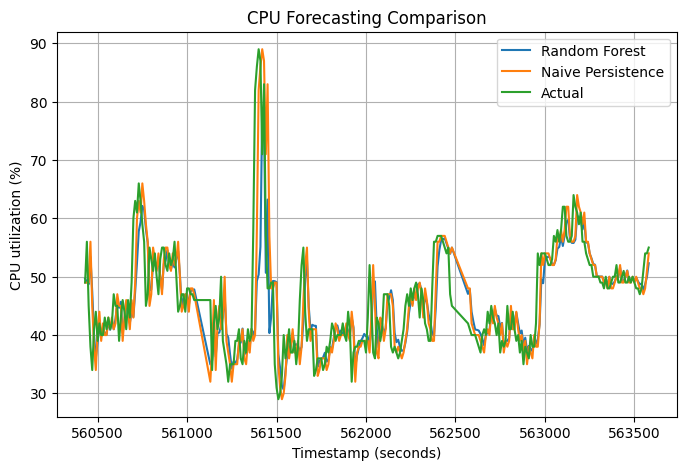

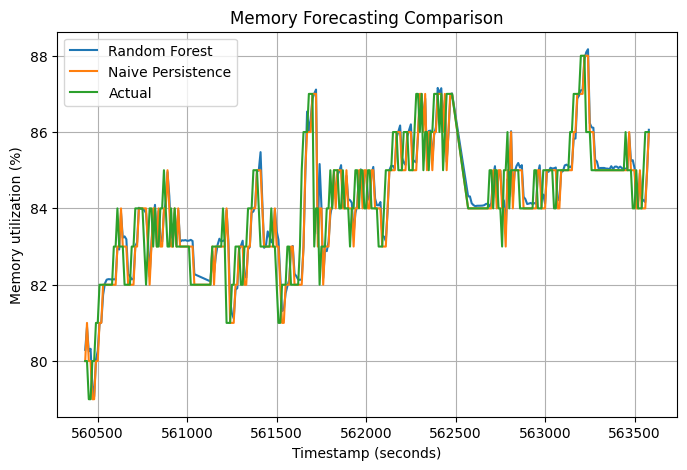

In [ ]:
import matplotlib.pyplot as plt

resources = ["CPU", "Memory"]

for resource in resources:
    plt.figure(figsize=(8, 5))

    plt.plot(
        test_df["time_stamp"].iloc[:300],
        (cpu_rf_pred if resource == "CPU" else mem_rf_pred)[:300],
        label="Random Forest"
    )

    plt.plot(
        test_df["time_stamp"].iloc[:300],
        (cpu_persistence_pred if resource == "CPU" else mem_persistence_pred)[:300],
        label="Naive Persistence"
    )

    actual = (
        test_df["cpu_target"] if resource == "CPU"
        else test_df["mem_target"]
    )

    plt.plot(
        test_df["time_stamp"].iloc[:300],
        actual.iloc[:300],
        label="Actual"
    )

    plt.xlabel("Timestamp (seconds)")
    plt.ylabel(f"{resource} utilization (%)")
    plt.title(f"{resource} Forecasting Comparison")
    plt.legend()
    plt.grid(True)
    plt.show()

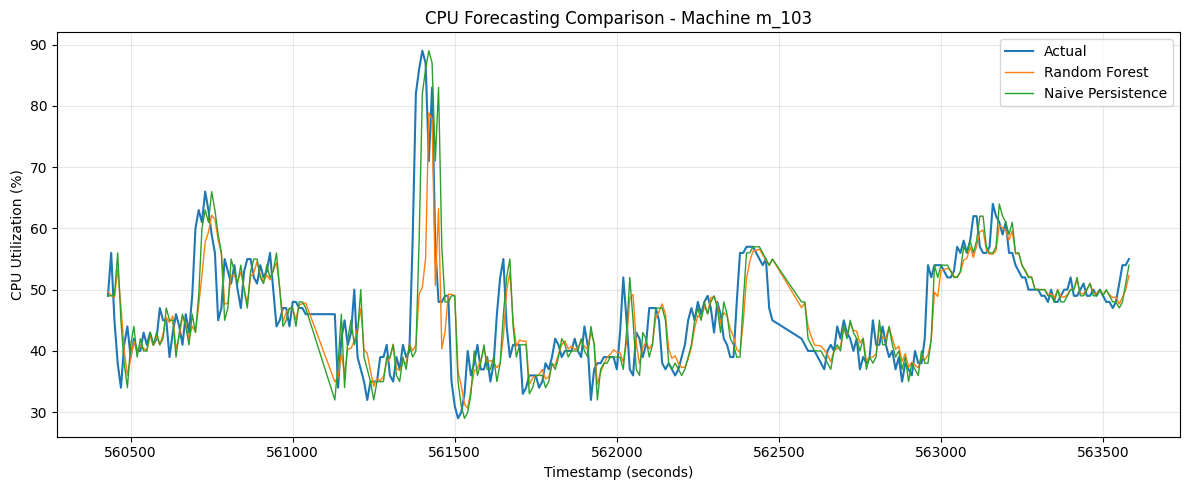

In [ ]:
import matplotlib.pyplot as plt
import os

plot_df = test_df[test_df["machine_id"] == "m_103"].head(300).copy()

os.makedirs(
    "/content/AgenticCloudManagement/results/graphs",
    exist_ok=True
)

# CPU graph
plt.figure(figsize=(12, 5))
plt.plot(plot_df["time_stamp"], plot_df["cpu_target"],
         label="Actual", linewidth=1.5)
plt.plot(plot_df["time_stamp"], cpu_rf_pred[:300],
         label="Random Forest", linewidth=1)
plt.plot(plot_df["time_stamp"], cpu_persistence_pred[:300],
         label="Naive Persistence", linewidth=1)

plt.xlabel("Timestamp (seconds)")
plt.ylabel("CPU Utilization (%)")
plt.title("CPU Forecasting Comparison - Machine m_103")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/AgenticCloudManagement/results/graphs/cpu_forecasting_m103.png",
    dpi=300
)
plt.show()

memory forcasting graph

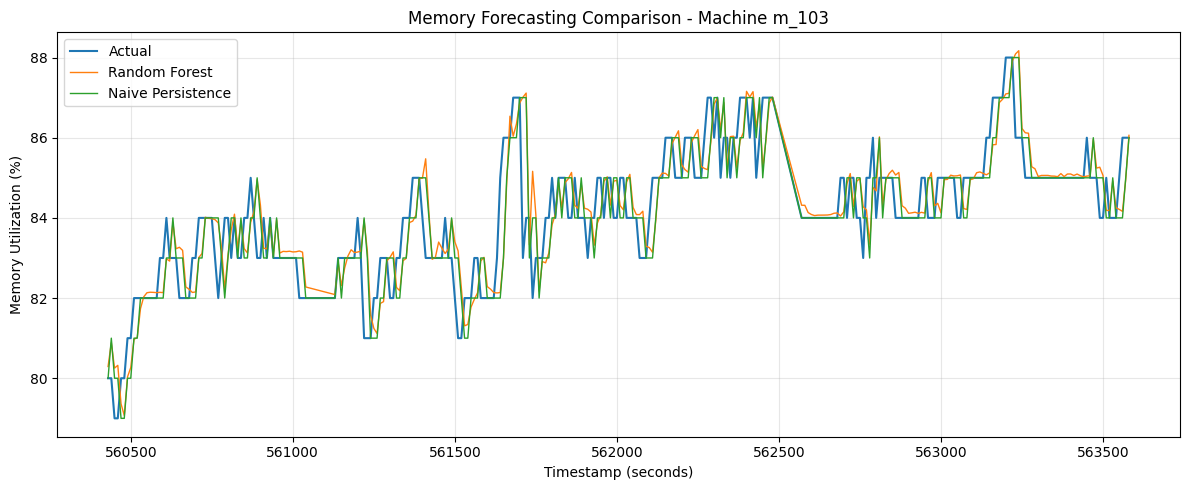

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    plot_df["time_stamp"],
    plot_df["mem_target"],
    label="Actual",
    linewidth=1.5
)

plt.plot(
    plot_df["time_stamp"],
    mem_rf_pred[:300],
    label="Random Forest",
    linewidth=1
)

plt.plot(
    plot_df["time_stamp"],
    mem_persistence_pred[:300],
    label="Naive Persistence",
    linewidth=1
)

plt.xlabel("Timestamp (seconds)")
plt.ylabel("Memory Utilization (%)")
plt.title("Memory Forecasting Comparison - Machine m_103")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/AgenticCloudManagement/results/graphs/memory_forecasting_m103.png",
    dpi=300
)

plt.show()

Resource Agent

In [ ]:
import os
import pandas as pd

# Create agents directory
os.makedirs(
    "/content/AgenticCloudManagement/agents",
    exist_ok=True
)

class ResourceAgent:

    def __init__(self, cpu_threshold=80, memory_threshold=85):
        self.cpu_threshold = cpu_threshold
        self.memory_threshold = memory_threshold

    def analyze_resources(self, data):

        required_columns = [
            "machine_id",
            "time_stamp",
            "cpu_util_percent",
            "mem_util_percent"
        ]

        missing = [
            col for col in required_columns
            if col not in data.columns
        ]

        if missing:
            raise ValueError(f"Missing columns: {missing}")

        # Get the latest observation for every machine
        latest = (
            data.sort_values("time_stamp")
            .groupby("machine_id")
            .tail(1)
            .copy()
        )

        results = []

        for _, row in latest.iterrows():

            cpu = float(row["cpu_util_percent"])
            memory = float(row["mem_util_percent"])

            cpu_available = 100 - cpu
            memory_available = 100 - memory

            cpu_pressure = cpu >= self.cpu_threshold
            memory_pressure = memory >= self.memory_threshold

            if cpu_pressure and memory_pressure:
                status = "BOTH_PRESSURE"

            elif cpu_pressure:
                status = "CPU_PRESSURE"

            elif memory_pressure:
                status = "MEMORY_PRESSURE"

            else:
                status = "NORMAL"

            results.append({
                "machine_id": row["machine_id"],
                "timestamp": row["time_stamp"],
                "current_cpu": cpu,
                "current_memory": memory,
                "available_cpu": cpu_available,
                "available_memory": memory_available,
                "resource_status": status
            })

        return pd.DataFrame(results)


# Initialize Resource Agent
resource_agent = ResourceAgent(
    cpu_threshold=80,
    memory_threshold=85
)

# Analyze the selected machines
resource_status_df = resource_agent.analyze_resources(selected_data)

display(resource_status_df.head(20))

,machine_id,timestamp,current_cpu,current_memory,available_cpu,available_memory,resource_status
0,m_2366,691180,44.0,92.0,56.0,8.0,MEMORY_PRESSURE
1,m_1863,691190,27.0,96.0,73.0,4.0,MEMORY_PRESSURE
2,m_694,691190,86.0,94.0,14.0,6.0,BOTH_PRESSURE
3,m_200,691190,22.0,95.0,78.0,5.0,MEMORY_PRESSURE
4,m_2014,691190,27.0,97.0,73.0,3.0,MEMORY_PRESSURE
5,m_1732,691190,26.0,92.0,74.0,8.0,MEMORY_PRESSURE
6,m_3330,691190,23.0,90.0,77.0,10.0,MEMORY_PRESSURE
7,m_2022,691190,88.0,93.0,12.0,7.0,BOTH_PRESSURE
8,m_1223,691190,15.0,95.0,85.0,5.0,MEMORY_PRESSURE
9,m_2274,691190,22.0,85.0,78.0,15.0,MEMORY_PRESSURE


In [ ]:
resource_status_df.to_csv(
    "/content/AgenticCloudManagement/results/resource_agent_results.csv",
    index=False
)

print("Resource Agent results saved successfully.")
print("Total machines:", len(resource_status_df))
print("\nStatus summary:")
print(resource_status_df["resource_status"].value_counts())

Resource Agent results saved successfully.
Total machines: 20

Status summary:
resource_status
MEMORY_PRESSURE    17
BOTH_PRESSURE       3
Name: count, dtype: int64


Performance Agent

In [ ]:
import numpy as np
import pandas as pd

class PerformanceAgent:

    def __init__(self, cpu_threshold=80, memory_threshold=85):
        self.cpu_threshold = cpu_threshold
        self.memory_threshold = memory_threshold

    def analyze_performance(
        self,
        test_data,
        cpu_rf,
        mem_rf,
        cpu_naive,
        mem_naive
    ):

        data = test_data.copy().reset_index(drop=True)

        # Verify prediction alignment
        if not all(
            len(pred) == len(data)
            for pred in [cpu_rf, mem_rf, cpu_naive, mem_naive]
        ):
            raise ValueError(
                "Prediction arrays must match test dataset length."
            )

        # Add model predictions
        data["cpu_rf_prediction"] = cpu_rf
        data["mem_rf_prediction"] = mem_rf

        data["cpu_naive_prediction"] = cpu_naive
        data["mem_naive_prediction"] = mem_naive

        # Calculate forecasting errors
        data["cpu_rf_error"] = abs(
            data["cpu_target"] - data["cpu_rf_prediction"]
        )

        data["mem_rf_error"] = abs(
            data["mem_target"] - data["mem_rf_prediction"]
        )

        # Determine forecast timestamp
        data["forecast_timestamp"] = (
            data["time_stamp"] + data["target_gap"]
        )

        # Get latest forecast for each machine
        latest = (
            data.sort_values("forecast_timestamp")
            .groupby("machine_id")
            .tail(1)
            .copy()
        )

        results = []

        for _, row in latest.iterrows():

            predicted_cpu = float(row["cpu_rf_prediction"])
            predicted_memory = float(row["mem_rf_prediction"])

            if (
                predicted_cpu >= self.cpu_threshold
                and predicted_memory >= self.memory_threshold
            ):
                status = "BOTH_PRESSURE"

            elif predicted_cpu >= self.cpu_threshold:
                status = "CPU_PRESSURE"

            elif predicted_memory >= self.memory_threshold:
                status = "MEMORY_PRESSURE"

            else:
                status = "NORMAL"

            results.append({

                "machine_id": row["machine_id"],

                "forecast_timestamp": row["forecast_timestamp"],

                "predicted_cpu": predicted_cpu,

                "predicted_memory": predicted_memory,

                "actual_cpu": float(row["cpu_target"]),

                "actual_memory": float(row["mem_target"]),

                "cpu_forecast_error": float(row["cpu_rf_error"]),

                "memory_forecast_error": float(row["mem_rf_error"]),

                "cpu_naive_prediction": float(
                    row["cpu_naive_prediction"]
                ),

                "memory_naive_prediction": float(
                    row["mem_naive_prediction"]
                ),

                "predicted_status": status
            })

        return pd.DataFrame(results)


# Initialize Performance Agent
performance_agent = PerformanceAgent(
    cpu_threshold=80,
    memory_threshold=85
)

# Analyse forecasting performance
performance_status_df = performance_agent.analyze_performance(
    test_df,
    cpu_rf_pred,
    mem_rf_pred,
    cpu_persistence_pred,
    mem_persistence_pred
)

display(performance_status_df)

,machine_id,forecast_timestamp,predicted_cpu,predicted_memory,actual_cpu,actual_memory,cpu_forecast_error,memory_forecast_error,cpu_naive_prediction,memory_naive_prediction,predicted_status
0,m_2366,691180.0,39.069084,92.185379,44.0,92.0,4.930916,0.185379,66.0,92.0,MEMORY_PRESSURE
1,m_3244,691190.0,81.229332,91.229452,89.0,91.0,7.770668,0.229452,89.0,91.0,BOTH_PRESSURE
2,m_2165,691190.0,30.404344,95.922607,33.0,97.0,2.595656,1.077393,29.0,96.0,MEMORY_PRESSURE
3,m_2148,691190.0,15.254255,93.242426,16.0,94.0,0.745745,0.757574,14.0,93.0,MEMORY_PRESSURE
4,m_132,691190.0,28.449778,94.738209,24.0,94.0,4.449778,0.738209,28.0,95.0,MEMORY_PRESSURE
5,m_2773,691190.0,17.054192,94.946109,18.0,95.0,0.945808,0.053891,16.0,95.0,MEMORY_PRESSURE
6,m_2022,691190.0,82.153673,91.924476,88.0,93.0,5.846327,1.075524,86.0,92.0,BOTH_PRESSURE
7,m_3330,691190.0,25.876337,90.065652,23.0,90.0,2.876337,0.065652,24.0,90.0,MEMORY_PRESSURE
8,m_2274,691190.0,22.090595,85.145207,22.0,85.0,0.090595,0.145207,20.0,85.0,MEMORY_PRESSURE
9,m_1223,691190.0,15.778995,94.672516,15.0,95.0,0.778995,0.327484,13.0,95.0,MEMORY_PRESSURE


In [ ]:
# Save Performance Agent results

performance_status_df.to_csv(
    "/content/AgenticCloudManagement/results/performance_agent_results.csv",
    index=False
)

print("Performance Agent results saved successfully.")

print("\nPredicted status summary:")
print(
    performance_status_df["predicted_status"].value_counts()
)

print("\nAverage forecast errors:")
print(
    performance_status_df[
        ["cpu_forecast_error", "memory_forecast_error"]
    ].mean().round(4)
)

Performance Agent results saved successfully.

Predicted status summary:
predicted_status
MEMORY_PRESSURE    17
BOTH_PRESSURE       3
Name: count, dtype: int64

Average forecast errors:
cpu_forecast_error       2.9523
memory_forecast_error    0.5886
dtype: float64


Cost Agent

In [ ]:
import pandas as pd

class CostAgent:

    def __init__(
        self,
        cpu_rate=0.05,
        memory_rate=0.03,
        duration_hours=1
    ):
        self.cpu_rate = cpu_rate
        self.memory_rate = memory_rate
        self.duration_hours = duration_hours

    def estimate_cost(self, resource_data):

        results = []

        for _, row in resource_data.iterrows():

            cpu = float(row["current_cpu"])
            memory = float(row["current_memory"])

            cpu_cost = (
                cpu * self.cpu_rate * self.duration_hours
            )

            memory_cost = (
                memory * self.memory_rate * self.duration_hours
            )

            total_cost = cpu_cost + memory_cost

            results.append({

                "machine_id": row["machine_id"],

                "cpu_utilization": cpu,

                "memory_utilization": memory,

                "estimated_cpu_cost": round(cpu_cost, 4),

                "estimated_memory_cost": round(memory_cost, 4),

                "total_estimated_cost": round(total_cost, 4)

            })

        return pd.DataFrame(results)


# Initialize Cost Agent
cost_agent = CostAgent(
    cpu_rate=0.05,
    memory_rate=0.03,
    duration_hours=1
)

# Estimate cost using Resource Agent measurements
cost_status_df = cost_agent.estimate_cost(resource_status_df)

display(cost_status_df)

,machine_id,cpu_utilization,memory_utilization,estimated_cpu_cost,estimated_memory_cost,total_estimated_cost
0,m_2366,44.0,92.0,2.20,2.76,4.96
1,m_1863,27.0,96.0,1.35,2.88,4.23
2,m_694,86.0,94.0,4.30,2.82,7.12
3,m_200,22.0,95.0,1.10,2.85,3.95
4,m_2014,27.0,97.0,1.35,2.91,4.26
5,m_1732,26.0,92.0,1.30,2.76,4.06
6,m_3330,23.0,90.0,1.15,2.70,3.85
7,m_2022,88.0,93.0,4.40,2.79,7.19
8,m_1223,15.0,95.0,0.75,2.85,3.60
9,m_2274,22.0,85.0,1.10,2.55,3.65


In [ ]:
cost_status_df.to_csv(
    "/content/AgenticCloudManagement/results/cost_agent_results.csv",
    index=False
)

print("Cost Agent results saved successfully.")

print("\nTotal estimated cost:")
print(
    round(cost_status_df["total_estimated_cost"].sum(), 2)
)

print("\nAverage cost per machine:")
print(
    round(cost_status_df["total_estimated_cost"].mean(), 2)
)

print("\nHighest cost machine:")
display(
    cost_status_df.nlargest(1, "total_estimated_cost")
)

Cost Agent results saved successfully.

Total estimated cost:
89.46

Average cost per machine:
4.47

Highest cost machine:


,machine_id,cpu_utilization,memory_utilization,estimated_cpu_cost,estimated_memory_cost,total_estimated_cost
7,m_2022,88.0,93.0,4.4,2.79,7.19


Security Agent

In [ ]:
import pandas as pd

class SecurityAgent:

    def __init__(
        self,
        cpu_threshold=90,
        memory_threshold=95
    ):
        self.cpu_threshold = cpu_threshold
        self.memory_threshold = memory_threshold

    def analyze_security(self, resource_data):

        results = []

        for _, row in resource_data.iterrows():

            cpu = float(row["current_cpu"])
            memory = float(row["current_memory"])

            alerts = []

            # Rule 1: Extremely high CPU utilization
            if cpu >= self.cpu_threshold:
                alerts.append("HIGH_CPU_USAGE")

            # Rule 2: Extremely high memory utilization
            if memory >= self.memory_threshold:
                alerts.append("HIGH_MEMORY_USAGE")

            # Determine security status
            if len(alerts) >= 2:
                status = "HIGH_RESOURCE_RISK"

            elif len(alerts) == 1:
                status = "MODERATE_RESOURCE_RISK"

            else:
                status = "NORMAL"

            results.append({

                "machine_id": row["machine_id"],

                "cpu_utilization": cpu,

                "memory_utilization": memory,

                "security_alerts": (
                    ", ".join(alerts) if alerts else "NONE"
                ),

                "security_status": status

            })

        return pd.DataFrame(results)


# Initialize Security Agent
security_agent = SecurityAgent(
    cpu_threshold=90,
    memory_threshold=95
)

# Analyse machine resource conditions
security_status_df = security_agent.analyze_security(
    resource_status_df
)

display(security_status_df)

,machine_id,cpu_utilization,memory_utilization,security_alerts,security_status
0,m_2366,44.0,92.0,NONE,NORMAL
1,m_1863,27.0,96.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
2,m_694,86.0,94.0,NONE,NORMAL
3,m_200,22.0,95.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
4,m_2014,27.0,97.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
5,m_1732,26.0,92.0,NONE,NORMAL
6,m_3330,23.0,90.0,NONE,NORMAL
7,m_2022,88.0,93.0,NONE,NORMAL
8,m_1223,15.0,95.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
9,m_2274,22.0,85.0,NONE,NORMAL


In [ ]:
security_status_df.to_csv(
    "/content/AgenticCloudManagement/results/security_agent_results.csv",
    index=False
)

print("Security Agent results saved successfully.")

print("\nSecurity status summary:")
print(security_status_df["security_status"].value_counts())

print("\nSecurity alerts:")
print(
    security_status_df[
        security_status_df["security_alerts"] != "NONE"
    ][["machine_id", "security_alerts", "security_status"]]
)

Security Agent results saved successfully.

Security status summary:
security_status
NORMAL                    13
MODERATE_RESOURCE_RISK     7
Name: count, dtype: int64

Security alerts:
   machine_id    security_alerts         security_status
1      m_1863  HIGH_MEMORY_USAGE  MODERATE_RESOURCE_RISK
3       m_200  HIGH_MEMORY_USAGE  MODERATE_RESOURCE_RISK
4      m_2014  HIGH_MEMORY_USAGE  MODERATE_RESOURCE_RISK
8      m_1223  HIGH_MEMORY_USAGE  MODERATE_RESOURCE_RISK
13     m_2773  HIGH_MEMORY_USAGE  MODERATE_RESOURCE_RISK
15     m_2967  HIGH_MEMORY_USAGE  MODERATE_RESOURCE_RISK
19     m_2165  HIGH_MEMORY_USAGE  MODERATE_RESOURCE_RISK


Implementation the Negotiation Coordinator

In [ ]:
import pandas as pd

class NegotiationCoordinator:

    def negotiate(
        self,
        resource_data,
        performance_data,
        cost_data,
        security_data
    ):

        # Combine all four agent outputs
        combined = (
            resource_data
            .merge(performance_data, on="machine_id")
            .merge(cost_data, on="machine_id")
            .merge(security_data, on="machine_id")
        )

        decisions = []

        for _, row in combined.iterrows():

            recommendations = []

            current_cpu = row["current_cpu"]
            current_memory = row["current_memory"]

            predicted_cpu = row["predicted_cpu"]
            predicted_memory = row["predicted_memory"]

            security_status = row["security_status"]

            # Resource Agent recommendation
            if current_cpu >= 80 or current_memory >= 85:
                resource_vote = "SCALE_UP"
            else:
                resource_vote = "MAINTAIN"

            recommendations.append(resource_vote)

            # Performance Agent recommendation
            if predicted_cpu >= 80 or predicted_memory >= 85:
                performance_vote = "SCALE_UP"
            else:
                performance_vote = "MAINTAIN"

            recommendations.append(performance_vote)

            # Cost Agent observation
            estimated_cost = row["total_estimated_cost"]

            # Security Agent recommendation
            if security_status == "HIGH_RESOURCE_RISK":
                security_vote = "BLOCK_SCALE_DOWN"
            else:
                security_vote = "NO_BLOCK"

            # Negotiation and conflict resolution
            if security_status == "HIGH_RESOURCE_RISK":
                final_decision = "MAINTAIN"

            elif (
                resource_vote == "SCALE_UP"
                or performance_vote == "SCALE_UP"
            ):
                final_decision = "SCALE_UP"

            elif (
                current_cpu < 30
                and current_memory < 70
                and predicted_cpu < 30
                and predicted_memory < 70
            ):
                final_decision = "SCALE_DOWN"

            else:
                final_decision = "MAINTAIN"

            # Explain the decision
            if final_decision == "SCALE_UP":
                explanation = (
                    "Resource pressure detected by current "
                    "or predicted utilization."
                )

            elif final_decision == "SCALE_DOWN":
                explanation = (
                    "Current and predicted utilization are low."
                )

            else:
                explanation = (
                    "No safe scaling action is justified "
                    "by the current negotiation rules."
                )

            decisions.append({

                "machine_id": row["machine_id"],

                "resource_vote": resource_vote,

                "performance_vote": performance_vote,

                "security_vote": security_vote,

                "estimated_cost": estimated_cost,

                "final_decision": final_decision,

                "explanation": explanation

            })

        return pd.DataFrame(decisions)


# Initialize coordinator
negotiation_coordinator = NegotiationCoordinator()

# Run multi-agent negotiation
negotiation_results_df = negotiation_coordinator.negotiate(
    resource_status_df,
    performance_status_df,
    cost_status_df,
    security_status_df
)

display(negotiation_results_df)

,machine_id,resource_vote,performance_vote,security_vote,estimated_cost,final_decision,explanation
0,m_2366,SCALE_UP,SCALE_UP,NO_BLOCK,4.96,SCALE_UP,Resource pressure detected by current or predi...
1,m_1863,SCALE_UP,SCALE_UP,NO_BLOCK,4.23,SCALE_UP,Resource pressure detected by current or predi...
2,m_694,SCALE_UP,SCALE_UP,NO_BLOCK,7.12,SCALE_UP,Resource pressure detected by current or predi...
3,m_200,SCALE_UP,SCALE_UP,NO_BLOCK,3.95,SCALE_UP,Resource pressure detected by current or predi...
4,m_2014,SCALE_UP,SCALE_UP,NO_BLOCK,4.26,SCALE_UP,Resource pressure detected by current or predi...
5,m_1732,SCALE_UP,SCALE_UP,NO_BLOCK,4.06,SCALE_UP,Resource pressure detected by current or predi...
6,m_3330,SCALE_UP,SCALE_UP,NO_BLOCK,3.85,SCALE_UP,Resource pressure detected by current or predi...
7,m_2022,SCALE_UP,SCALE_UP,NO_BLOCK,7.19,SCALE_UP,Resource pressure detected by current or predi...
8,m_1223,SCALE_UP,SCALE_UP,NO_BLOCK,3.60,SCALE_UP,Resource pressure detected by current or predi...
9,m_2274,SCALE_UP,SCALE_UP,NO_BLOCK,3.65,SCALE_UP,Resource pressure detected by current or predi...


In [ ]:
negotiation_results_df.to_csv(
    "/content/AgenticCloudManagement/results/negotiation_results_v1.csv",
    index=False
)

print("Negotiation results saved successfully.")

print("\nFinal decision summary:")
print(negotiation_results_df["final_decision"].value_counts())

print("\nAgent voting summary:")
print("Resource Agent:")
print(negotiation_results_df["resource_vote"].value_counts())

print("\nPerformance Agent:")
print(negotiation_results_df["performance_vote"].value_counts())

Negotiation results saved successfully.

Final decision summary:
final_decision
SCALE_UP    20
Name: count, dtype: int64

Agent voting summary:
Resource Agent:
resource_vote
SCALE_UP    20
Name: count, dtype: int64

Performance Agent:
performance_vote
SCALE_UP    20
Name: count, dtype: int64


improved negociation

In [ ]:
class ImprovedNegotiationCoordinator:

    def negotiate(
        self,
        resource_data,
        performance_data,
        cost_data,
        security_data
    ):

        combined = (
            resource_data
            .merge(performance_data, on="machine_id")
            .merge(cost_data, on="machine_id")
            .merge(security_data, on="machine_id")
        )

        decisions = []

        for _, row in combined.iterrows():

            current_cpu = row["current_cpu"]
            current_memory = row["current_memory"]

            predicted_cpu = row["predicted_cpu"]
            predicted_memory = row["predicted_memory"]

            estimated_cost = row["total_estimated_cost"]

            # Resource Agent
            if current_cpu >= 80 or current_memory >= 85:
                resource_vote = "SCALE_UP"
            else:
                resource_vote = "MAINTAIN"

            # Performance Agent
            if predicted_cpu >= 80 or predicted_memory >= 85:
                performance_vote = "SCALE_UP"
            else:
                performance_vote = "MAINTAIN"

            # Cost Agent
            if estimated_cost > 5:
                cost_vote = "COST_WARNING"
            else:
                cost_vote = "COST_ACCEPTABLE"

            # Security Agent: use its actual output
            if row["security_status"] in [
                "HIGH_RESOURCE_RISK",
                "MODERATE_RESOURCE_RISK",
                "RESOURCE_RISK"
            ]:
                security_vote = "RESOURCE_RISK"
            else:
                security_vote = "SAFE"

            # Conflict resolution
            if security_vote == "RESOURCE_RISK":
                final_decision = "MAINTAIN"

            elif (
                resource_vote == "SCALE_UP"
                or performance_vote == "SCALE_UP"
            ):
                final_decision = "SCALE_UP"

            elif (
                current_cpu < 30
                and current_memory < 70
                and predicted_cpu < 30
                and predicted_memory < 70
            ):
                final_decision = "SCALE_DOWN"

            else:
                final_decision = "MAINTAIN"

            # Explainability
            if final_decision == "MAINTAIN" and security_vote == "RESOURCE_RISK":
                explanation = "Security policy overrides scaling recommendation."

            elif final_decision == "SCALE_UP":
                explanation = "Current or predicted resource pressure requires additional capacity."

            elif final_decision == "SCALE_DOWN":
                explanation = "Current and predicted resource utilization are low."

            else:
                explanation = "No scaling action is justified by current policies."

            decisions.append({
                "machine_id": row["machine_id"],
                "resource_vote": resource_vote,
                "performance_vote": performance_vote,
                "cost_vote": cost_vote,
                "security_vote": security_vote,
                "estimated_cost": estimated_cost,
                "final_decision": final_decision,
                "explanation": explanation
            })

        return pd.DataFrame(decisions)


# Reinitialize corrected coordinator
improved_coordinator = ImprovedNegotiationCoordinator()

print("Negotiation Coordinator updated successfully.")

Negotiation Coordinator updated successfully.


In [ ]:
improved_negotiation_df.to_csv(
    "/content/AgenticCloudManagement/results/improved_negotiation_results.csv",
    index=False
)

print("Improved negotiation results saved.")

print("\nFinal decision distribution:")
print(improved_negotiation_df["final_decision"].value_counts())

print("\nAgent recommendations:")
for agent in [
    "resource_vote",
    "performance_vote",
    "cost_vote",
    "security_vote"
]:
    print(f"\n{agent}")
    print(improved_negotiation_df[agent].value_counts())

Improved negotiation results saved.

Final decision distribution:
final_decision
SCALE_UP    13
MAINTAIN     7
Name: count, dtype: int64

Agent recommendations:

resource_vote
resource_vote
SCALE_UP    20
Name: count, dtype: int64

performance_vote
performance_vote
SCALE_UP    20
Name: count, dtype: int64

cost_vote
cost_vote
COST_ACCEPTABLE    17
COST_WARNING        3
Name: count, dtype: int64

security_vote
security_vote
SAFE             13
RESOURCE_RISK     7
Name: count, dtype: int64


explanation module

In [ ]:
import pandas as pd

class ExplainableDecisionAgent:

    def generate_explanations(self, negotiation_data):

        explanations = []

        for _, row in negotiation_data.iterrows():

            if row["final_decision"] == "MAINTAIN":

                reason = (
                    "Security policy detected resource risk. "
                    "Scaling action was restricted."
                )

                priority = "SECURITY_PRIORITY"

            elif row["final_decision"] == "SCALE_UP":

                reason = (
                    "Current and predicted resource pressure "
                    "indicate the need for additional capacity."
                )

                priority = "RESOURCE_PRIORITY"

            else:

                reason = (
                    "Current and predicted utilization are low. "
                    "Scaling down is permitted."
                )

                priority = "COST_AND_RESOURCE_POLICY"

            explanations.append({

                "machine_id": row["machine_id"],

                "final_decision": row["final_decision"],

                "resource_agent": row["resource_vote"],

                "performance_agent": row["performance_vote"],

                "cost_agent": row["cost_vote"],

                "security_agent": row["security_vote"],

                "decision_priority": priority,

                "decision_explanation": reason

            })

        return pd.DataFrame(explanations)


# Initialize explainability module
explanation_agent = ExplainableDecisionAgent()

# Generate explanations
explainable_results_df = (
    explanation_agent.generate_explanations(
        improved_negotiation_df
    )
)

display(explainable_results_df)

,machine_id,final_decision,resource_agent,performance_agent,cost_agent,security_agent,decision_priority,decision_explanation
0,m_2366,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
1,m_1863,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
2,m_694,SCALE_UP,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
3,m_200,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
4,m_2014,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
5,m_1732,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
6,m_3330,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
7,m_2022,SCALE_UP,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
8,m_1223,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
9,m_2274,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...


In [ ]:
explainable_results_df.to_csv(
    "/content/AgenticCloudManagement/results/explainable_decisions.csv",
    index=False
)

print("Explainable decision results saved.")

print("\nDecision distribution:")
print(explainable_results_df["final_decision"].value_counts())

print("\nPriority distribution:")
print(explainable_results_df["decision_priority"].value_counts())

Explainable decision results saved.

Decision distribution:
final_decision
SCALE_UP    13
MAINTAIN     7
Name: count, dtype: int64

Priority distribution:
decision_priority
RESOURCE_PRIORITY    13
SECURITY_PRIORITY     7
Name: count, dtype: int64


negociation test on three scenarios

In [ ]:
import pandas as pd

test_scenarios = pd.DataFrame([
    {
        "scenario": "High resource pressure",
        "current_cpu": 90,
        "current_memory": 92,
        "predicted_cpu": 88,
        "predicted_memory": 91,
        "estimated_cost": 4.0,
        "security_status": "SAFE"
    },
    {
        "scenario": "Security risk",
        "current_cpu": 45,
        "current_memory": 96,
        "predicted_cpu": 50,
        "predicted_memory": 94,
        "estimated_cost": 4.0,
        "security_status": "RESOURCE_RISK"
    },
    {
        "scenario": "Low resource utilization",
        "current_cpu": 20,
        "current_memory": 40,
        "predicted_cpu": 22,
        "predicted_memory": 42,
        "estimated_cost": 4.0,
        "security_status": "SAFE"
    }
])

display(test_scenarios)

,scenario,current_cpu,current_memory,predicted_cpu,predicted_memory,estimated_cost,security_status
0,High resource pressure,90,92,88,91,4.0,SAFE
1,Security risk,45,96,50,94,4.0,RESOURCE_RISK
2,Low resource utilization,20,40,22,42,4.0,SAFE


In [ ]:
# Create inputs for the four agents

test_resource = test_scenarios[
    ["current_cpu", "current_memory"]
].copy()

test_resource["machine_id"] = ["TEST_1", "TEST_2", "TEST_3"]


test_performance = test_scenarios[
    ["predicted_cpu", "predicted_memory"]
].copy()

test_performance["machine_id"] = ["TEST_1", "TEST_2", "TEST_3"]


test_cost = pd.DataFrame({
    "machine_id": ["TEST_1", "TEST_2", "TEST_3"],
    "total_estimated_cost": test_scenarios["estimated_cost"]
})


test_security = pd.DataFrame({
    "machine_id": ["TEST_1", "TEST_2", "TEST_3"],
    "security_status": test_scenarios["security_status"]
})


# Execute the actual negotiation coordinator

scenario_results = improved_coordinator.negotiate(
    test_resource,
    test_performance,
    test_cost,
    test_security
)

# Attach scenario names
scenario_results["scenario"] = test_scenarios["scenario"].values

display(
    scenario_results[
        [
            "scenario",
            "resource_vote",
            "performance_vote",
            "cost_vote",
            "security_vote",
            "final_decision"
        ]
    ]
)

# Verify expected decisions
expected = ["SCALE_UP", "MAINTAIN", "SCALE_DOWN"]

actual = scenario_results["final_decision"].tolist()

print("\nExpected decisions:", expected)
print("Actual decisions:  ", actual)

if actual == expected:
    print("\nSUCCESS: All three negotiation scenarios passed!")
else:
    print("\nSome scenarios failed. We need to inspect the rules.")

,scenario,resource_vote,performance_vote,cost_vote,security_vote,final_decision
0,High resource pressure,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,SCALE_UP
1,Security risk,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,MAINTAIN
2,Low resource utilization,MAINTAIN,MAINTAIN,COST_ACCEPTABLE,SAFE,SCALE_DOWN



Expected decisions: ['SCALE_UP', 'MAINTAIN', 'SCALE_DOWN']
Actual decisions:   ['SCALE_UP', 'MAINTAIN', 'SCALE_DOWN']

SUCCESS: All three negotiation scenarios passed!


In [ ]:
# Run corrected negotiation on real dataset

final_negotiation_df = improved_coordinator.negotiate(
    resource_status_df,
    performance_status_df,
    cost_status_df,
    security_status_df
)

display(final_negotiation_df)

print("\nFinal decision distribution:")
print(final_negotiation_df["final_decision"].value_counts())

,machine_id,resource_vote,performance_vote,cost_vote,security_vote,estimated_cost,final_decision,explanation
0,m_2366,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,4.96,SCALE_UP,Current or predicted resource pressure require...
1,m_1863,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,4.23,MAINTAIN,Security policy overrides scaling recommendation.
2,m_694,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,7.12,SCALE_UP,Current or predicted resource pressure require...
3,m_200,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,3.95,MAINTAIN,Security policy overrides scaling recommendation.
4,m_2014,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,4.26,MAINTAIN,Security policy overrides scaling recommendation.
5,m_1732,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,4.06,SCALE_UP,Current or predicted resource pressure require...
6,m_3330,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,3.85,SCALE_UP,Current or predicted resource pressure require...
7,m_2022,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,7.19,SCALE_UP,Current or predicted resource pressure require...
8,m_1223,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,3.60,MAINTAIN,Security policy overrides scaling recommendation.
9,m_2274,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,3.65,SCALE_UP,Current or predicted resource pressure require...



Final decision distribution:
final_decision
SCALE_UP    13
MAINTAIN     7
Name: count, dtype: int64


In [ ]:
final_negotiation_df.to_csv(
    "/content/AgenticCloudManagement/results/final_negotiation_results.csv",
    index=False
)

print("Final negotiation results saved successfully.")

Final negotiation results saved successfully.


In [ ]:
# Generate explanations from corrected negotiation results

explainable_results_df = (
    explanation_agent.generate_explanations(
        final_negotiation_df
    )
)

display(explainable_results_df)

# Save corrected explanations
explainable_results_df.to_csv(
    "/content/AgenticCloudManagement/results/final_explainable_decisions.csv",
    index=False
)

print("Final explainable decisions saved successfully.")

,machine_id,final_decision,resource_agent,performance_agent,cost_agent,security_agent,decision_priority,decision_explanation
0,m_2366,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
1,m_1863,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
2,m_694,SCALE_UP,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
3,m_200,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
4,m_2014,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
5,m_1732,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
6,m_3330,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
7,m_2022,SCALE_UP,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
8,m_1223,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
9,m_2274,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...


Final explainable decisions saved successfully.


evalution graph

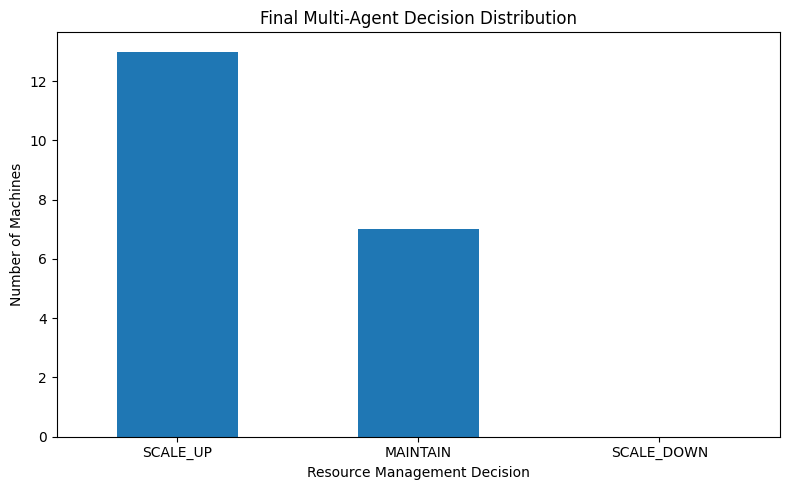

In [ ]:
import matplotlib.pyplot as plt

decision_counts = (
    final_negotiation_df["final_decision"]
    .value_counts()
    .reindex(["SCALE_UP", "MAINTAIN", "SCALE_DOWN"], fill_value=0)
)

plt.figure(figsize=(8, 5))

decision_counts.plot(kind="bar")

plt.title("Final Multi-Agent Decision Distribution")
plt.xlabel("Resource Management Decision")
plt.ylabel("Number of Machines")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "/content/AgenticCloudManagement/results/graphs/final_decision_distribution.png",
    dpi=300
)

plt.show()

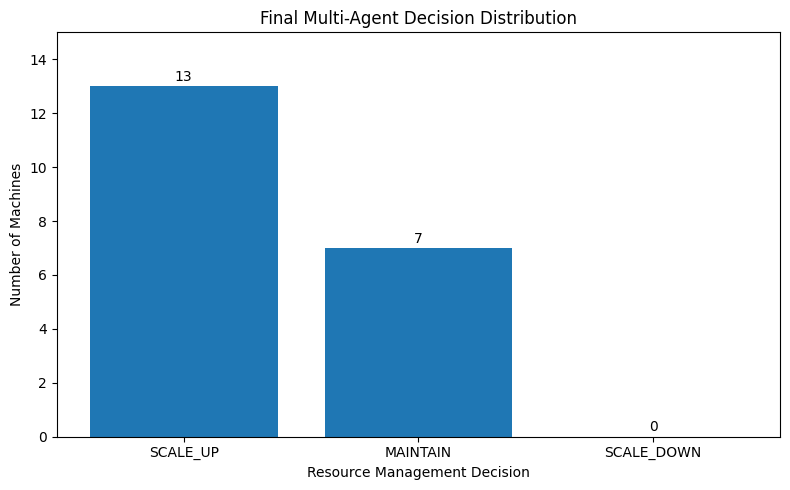

In [ ]:
import matplotlib.pyplot as plt

decision_counts = (
    final_negotiation_df["final_decision"]
    .value_counts()
    .reindex(["SCALE_UP", "MAINTAIN", "SCALE_DOWN"], fill_value=0)
)

plt.figure(figsize=(8, 5))

bars = plt.bar(decision_counts.index, decision_counts.values)

plt.title("Final Multi-Agent Decision Distribution")
plt.xlabel("Resource Management Decision")
plt.ylabel("Number of Machines")
plt.ylim(0, 15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "/content/AgenticCloudManagement/results/graphs/final_decision_distribution.png",
    dpi=300
)

plt.show()

voting of four agents graph


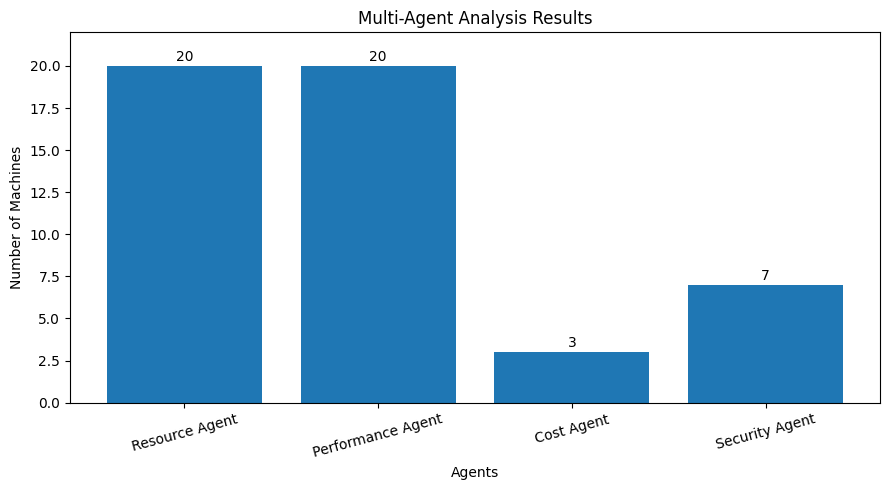

In [ ]:
import matplotlib.pyplot as plt

vote_counts = {
    "Resource Agent": final_negotiation_df["resource_vote"].value_counts().get("SCALE_UP", 0),
    "Performance Agent": final_negotiation_df["performance_vote"].value_counts().get("SCALE_UP", 0),
    "Cost Agent": final_negotiation_df["cost_vote"].value_counts().get("COST_WARNING", 0),
    "Security Agent": final_negotiation_df["security_vote"].value_counts().get("RESOURCE_RISK", 0)
}

plt.figure(figsize=(9, 5))

bars = plt.bar(vote_counts.keys(), vote_counts.values())

plt.title("Multi-Agent Analysis Results")
plt.xlabel("Agents")
plt.ylabel("Number of Machines")
plt.ylim(0, 22)
plt.xticks(rotation=15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "/content/AgenticCloudManagement/results/graphs/agent_analysis_results.png",
    dpi=300
)

plt.show()

negotiation table

In [ ]:
final_report_table = final_negotiation_df[
    [
        "machine_id",
        "resource_vote",
        "performance_vote",
        "cost_vote",
        "security_vote",
        "final_decision"
    ]
].copy()

display(final_report_table)

final_report_table.to_csv(
    "/content/AgenticCloudManagement/results/tables/final_negotiation_report.csv",
    index=False
)

,machine_id,resource_vote,performance_vote,cost_vote,security_vote,final_decision
0,m_2366,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,SCALE_UP
1,m_1863,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,MAINTAIN
2,m_694,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,SCALE_UP
3,m_200,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,MAINTAIN
4,m_2014,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,MAINTAIN
5,m_1732,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,SCALE_UP
6,m_3330,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,SCALE_UP
7,m_2022,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,SCALE_UP
8,m_1223,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,MAINTAIN
9,m_2274,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,SCALE_UP


verifing Explations

In [ ]:
print("Available columns:")
print(explainable_results_df.columns.tolist())

print("\nFirst 5 rows:")
display(explainable_results_df.head())

Available columns:
['machine_id', 'final_decision', 'resource_agent', 'performance_agent', 'cost_agent', 'security_agent', 'decision_priority', 'decision_explanation']

First 5 rows:


,machine_id,final_decision,resource_agent,performance_agent,cost_agent,security_agent,decision_priority,decision_explanation
0,m_2366,SCALE_UP,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
1,m_1863,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
2,m_694,SCALE_UP,SCALE_UP,SCALE_UP,COST_WARNING,SAFE,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
3,m_200,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
4,m_2014,MAINTAIN,SCALE_UP,SCALE_UP,COST_ACCEPTABLE,RESOURCE_RISK,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...


explainition table

In [ ]:
explainability_report = explainable_results_df[
    [
        "machine_id",
        "final_decision",
        "decision_priority",
        "decision_explanation"
    ]
].copy()

display(explainability_report)

explainability_report.to_csv(
    "/content/AgenticCloudManagement/results/tables/explainability_report.csv",
    index=False
)

,machine_id,final_decision,decision_priority,decision_explanation
0,m_2366,SCALE_UP,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
1,m_1863,MAINTAIN,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
2,m_694,SCALE_UP,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
3,m_200,MAINTAIN,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
4,m_2014,MAINTAIN,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
5,m_1732,SCALE_UP,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
6,m_3330,SCALE_UP,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
7,m_2022,SCALE_UP,RESOURCE_PRIORITY,Current and predicted resource pressure indica...
8,m_1223,MAINTAIN,SECURITY_PRIORITY,Security policy detected resource risk. Scalin...
9,m_2274,SCALE_UP,RESOURCE_PRIORITY,Current and predicted resource pressure indica...


explainition table graph

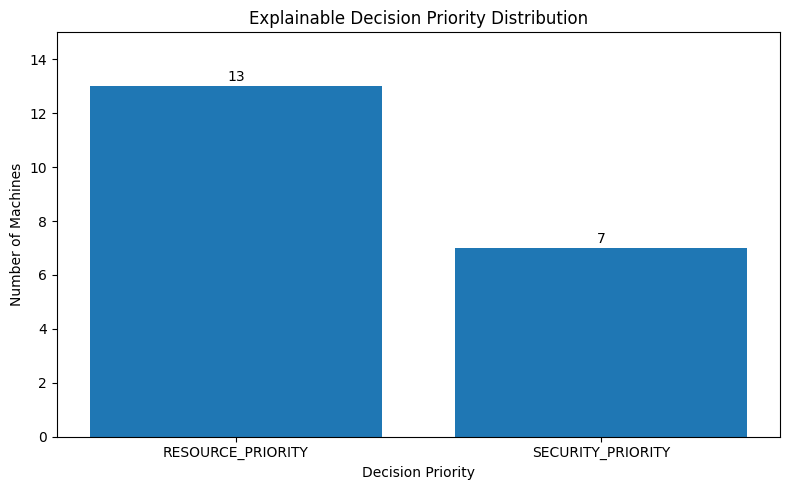

In [ ]:
import matplotlib.pyplot as plt

priority_counts = (
    explainability_report["decision_priority"]
    .value_counts()
    .reindex(
        ["RESOURCE_PRIORITY", "SECURITY_PRIORITY"],
        fill_value=0
    )
)

plt.figure(figsize=(8, 5))

bars = plt.bar(priority_counts.index, priority_counts.values)

plt.title("Explainable Decision Priority Distribution")
plt.xlabel("Decision Priority")
plt.ylabel("Number of Machines")
plt.ylim(0, 15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "/content/AgenticCloudManagement/results/graphs/explainability_distribution.png",
    dpi=300
)

plt.show()

check machines

In [ ]:
print("FINAL SYSTEM VALIDATION")

print("Total machines:", final_negotiation_df["machine_id"].nunique())

print(
    "Duplicate machine decisions:",
    final_negotiation_df["machine_id"].duplicated().sum()
)

print(
    "Missing final decisions:",
    final_negotiation_df["final_decision"].isna().sum()
)

print(
    "Missing explanations:",
    explainable_results_df["decision_explanation"].isna().sum()
)

print(
    "Decision counts:\n",
    final_negotiation_df["final_decision"].value_counts()
)

print(
    "Explanation records:",
    len(explainable_results_df)
)

FINAL SYSTEM VALIDATION
Total machines: 20
Duplicate machine decisions: 0
Missing final decisions: 0
Missing explanations: 0
Decision counts:
 final_decision
SCALE_UP    13
MAINTAIN     7
Name: count, dtype: int64
Explanation records: 20


In [ ]:
import pandas as pd

system_summary = pd.DataFrame({
    "Metric": [
        "Dataset",
        "Selected Machines",
        "Forecasting Test Samples",
        "CPU Random Forest MAE",
        "CPU Persistence MAE",
        "Memory Random Forest MAE",
        "Memory Persistence MAE",
        "SCALE_UP Decisions",
        "MAINTAIN Decisions",
        "SCALE_DOWN Decisions",
        "Security Resource Risks",
        "Cost Warnings",
        "Missing Decisions",
        "Missing Explanations"
    ],
    "Result": [
        "Alibaba Cluster Trace 2018",
        20,
        len(test_df),
        3.7971,
        3.8393,
        0.5859,
        0.5325,
        13,
        7,
        0,
        7,
        3,
        0,
        0
    ]
})

display(system_summary)

system_summary.to_csv(
    "/content/AgenticCloudManagement/results/tables/system_evaluation_summary.csv",
    index=False
)

,Metric,Result
0,Dataset,Alibaba Cluster Trace 2018
1,Selected Machines,20
2,Forecasting Test Samples,257571
3,CPU Random Forest MAE,3.7971
4,CPU Persistence MAE,3.8393
5,Memory Random Forest MAE,0.5859
6,Memory Persistence MAE,0.5325
7,SCALE_UP Decisions,13
8,MAINTAIN Decisions,7
9,SCALE_DOWN Decisions,0


negotiation logic

In [ ]:
import dis

print("===== SECURITY AGENT METHODS =====")

for name, method in SecurityAgent.__dict__.items():
    if callable(method) and hasattr(method, "__code__"):
        print(f"\n--- Method: {name} ---")
        dis.dis(method)

print("\n===== NEGOTIATION COORDINATOR METHODS =====")

for name, method in ImprovedNegotiationCoordinator.__dict__.items():
    if callable(method) and hasattr(method, "__code__"):
        print(f"\n--- Method: {name} ---")
        dis.dis(method)

===== SECURITY AGENT METHODS =====

--- Method: __init__ ---
  5           RESUME                   0

 10           LOAD_FAST_LOAD_FAST     16 (cpu_threshold, self)
              STORE_ATTR               0 (cpu_threshold)

 11           LOAD_FAST_LOAD_FAST     32 (memory_threshold, self)
              STORE_ATTR               1 (memory_threshold)
              RETURN_CONST             0 (None)

--- Method: analyze_security ---
 13           RESUME                   0

 15           BUILD_LIST               0
              STORE_FAST               2 (results)

 17           LOAD_FAST                1 (resource_data)
              LOAD_ATTR                1 (iterrows + NULL|self)
              CALL                     0
              GET_ITER
      L1:     FOR_ITER               187 (to L9)
              UNPACK_SEQUENCE          2
              STORE_FAST_STORE_FAST   52 (_, row)

 19           LOAD_GLOBAL              3 (float + NULL)
              LOAD_FAST                4 (row)
    

In [ ]:
print("MACHINES FLAGGED BY SECURITY AGENT")

security_risk_details = security_status_df[
    security_status_df["security_status"].isin(
        ["HIGH_RESOURCE_RISK", "MODERATE_RESOURCE_RISK", "RESOURCE_RISK"]
    )
].copy()

display(security_risk_details)

print("\nTotal flagged machines:",
      len(security_risk_details))

MACHINES FLAGGED BY SECURITY AGENT


,machine_id,cpu_utilization,memory_utilization,security_alerts,security_status
1,m_1863,27.0,96.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
3,m_200,22.0,95.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
4,m_2014,27.0,97.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
8,m_1223,15.0,95.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
13,m_2773,18.0,95.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
15,m_2967,21.0,95.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK
19,m_2165,33.0,97.0,HIGH_MEMORY_USAGE,MODERATE_RESOURCE_RISK



Total flagged machines: 7


In [ ]:
risk_forecast_check = (
    performance_status_df[
        performance_status_df["machine_id"].isin(
            security_risk_details["machine_id"]
        )
    ][
        [
            "machine_id",
            "predicted_cpu",
            "predicted_memory",
            "actual_cpu",
            "actual_memory"
        ]
    ]
    .merge(
        security_risk_details[
            ["machine_id", "security_status"]
        ],
        on="machine_id"
    )
)

display(risk_forecast_check)

,machine_id,predicted_cpu,predicted_memory,actual_cpu,actual_memory,security_status
0,m_2165,30.404344,95.922607,33.0,97.0,MODERATE_RESOURCE_RISK
1,m_2773,17.054192,94.946109,18.0,95.0,MODERATE_RESOURCE_RISK
2,m_1223,15.778995,94.672516,15.0,95.0,MODERATE_RESOURCE_RISK
3,m_2014,35.595796,96.499880,27.0,97.0,MODERATE_RESOURCE_RISK
4,m_200,26.772554,94.200077,22.0,95.0,MODERATE_RESOURCE_RISK
5,m_1863,28.749248,95.930054,27.0,96.0,MODERATE_RESOURCE_RISK
6,m_2967,20.532049,94.006783,21.0,95.0,MODERATE_RESOURCE_RISK


In [ ]:
def improved_decision_test(
    current_cpu,
    current_memory,
    predicted_cpu,
    predicted_memory,
    security_status
):
    if security_status == "HIGH_RESOURCE_RISK":
        return "SAFE_MITIGATION"

    if (
        current_cpu >= 80 or
        current_memory >= 85 or
        predicted_cpu >= 80 or
        predicted_memory >= 85
    ):
        return "SCALE_UP"

    if (
        current_cpu < 30 and
        current_memory < 70 and
        predicted_cpu < 30 and
        predicted_memory < 70
    ):
        return "SCALE_DOWN"

    return "MAINTAIN"


test_cases = [
    {
        "scenario": "High memory pressure",
        "current_cpu": 27,
        "current_memory": 96,
        "predicted_cpu": 29,
        "predicted_memory": 95,
        "security_status": "MODERATE_RESOURCE_RISK"
    },
    {
        "scenario": "High CPU pressure",
        "current_cpu": 92,
        "current_memory": 65,
        "predicted_cpu": 88,
        "predicted_memory": 66,
        "security_status": "MODERATE_RESOURCE_RISK"
    },
    {
        "scenario": "Critical resource risk",
        "current_cpu": 95,
        "current_memory": 98,
        "predicted_cpu": 94,
        "predicted_memory": 97,
        "security_status": "HIGH_RESOURCE_RISK"
    },
    {
        "scenario": "Low resource utilization",
        "current_cpu": 20,
        "current_memory": 50,
        "predicted_cpu": 22,
        "predicted_memory": 52,
        "security_status": "NORMAL"
    }
]

for case in test_cases:
    decision = improved_decision_test(
        case["current_cpu"],
        case["current_memory"],
        case["predicted_cpu"],
        case["predicted_memory"],
        case["security_status"]
    )

    print(case["scenario"], ":", decision)

High memory pressure : SCALE_UP
High CPU pressure : SCALE_UP
Critical resource risk : SAFE_MITIGATION
Low resource utilization : SCALE_DOWN


In [ ]:
comparison_df = final_negotiation_df[
    ["machine_id", "final_decision"]
].merge(
    risk_forecast_check[
        ["machine_id", "predicted_cpu", "predicted_memory"]
    ],
    on="machine_id",
    how="left"
).merge(
    resource_status_df[
        ["machine_id", "current_cpu", "current_memory"]
    ],
    on="machine_id",
    how="left"
).merge(
    security_status_df[
        ["machine_id", "security_status"]
    ],
    on="machine_id",
    how="left"
)

# Apply improved policy to all 20 machines
comparison_df["improved_decision"] = comparison_df.apply(
    lambda row: improved_decision_test(
        row["current_cpu"],
        row["current_memory"],
        row["predicted_cpu"],
        row["predicted_memory"],
        row["security_status"]
    ),
    axis=1
)

display(comparison_df)

print("\nOriginal decisions:")
print(comparison_df["final_decision"].value_counts())

print("\nImproved decisions:")
print(comparison_df["improved_decision"].value_counts())

,machine_id,final_decision,predicted_cpu,predicted_memory,current_cpu,current_memory,security_status,improved_decision
0,m_2366,SCALE_UP,NaN,NaN,44.0,92.0,NORMAL,SCALE_UP
1,m_1863,MAINTAIN,28.749248,95.930054,27.0,96.0,MODERATE_RESOURCE_RISK,SCALE_UP
2,m_694,SCALE_UP,NaN,NaN,86.0,94.0,NORMAL,SCALE_UP
3,m_200,MAINTAIN,26.772554,94.200077,22.0,95.0,MODERATE_RESOURCE_RISK,SCALE_UP
4,m_2014,MAINTAIN,35.595796,96.499880,27.0,97.0,MODERATE_RESOURCE_RISK,SCALE_UP
5,m_1732,SCALE_UP,NaN,NaN,26.0,92.0,NORMAL,SCALE_UP
6,m_3330,SCALE_UP,NaN,NaN,23.0,90.0,NORMAL,SCALE_UP
7,m_2022,SCALE_UP,NaN,NaN,88.0,93.0,NORMAL,SCALE_UP
8,m_1223,MAINTAIN,15.778995,94.672516,15.0,95.0,MODERATE_RESOURCE_RISK,SCALE_UP
9,m_2274,SCALE_UP,NaN,NaN,22.0,85.0,NORMAL,SCALE_UP



Original decisions:
final_decision
SCALE_UP    13
MAINTAIN     7
Name: count, dtype: int64

Improved decisions:
improved_decision
SCALE_UP    20
Name: count, dtype: int64


In [ ]:
comparison_df = final_negotiation_df[
    ["machine_id", "final_decision"]
].merge(
    performance_status_df[
        ["machine_id", "predicted_cpu", "predicted_memory"]
    ],
    on="machine_id",
    how="left"
).merge(
    resource_status_df[
        ["machine_id", "current_cpu", "current_memory"]
    ],
    on="machine_id",
    how="left"
).merge(
    security_status_df[
        ["machine_id", "security_status"]
    ],
    on="machine_id",
    how="left"
)

comparison_df["improved_decision"] = comparison_df.apply(
    lambda row: improved_decision_test(
        row["current_cpu"],
        row["current_memory"],
        row["predicted_cpu"],
        row["predicted_memory"],
        row["security_status"]
    ),
    axis=1
)

display(comparison_df)

print("\nMissing CPU forecasts:",
      comparison_df["predicted_cpu"].isna().sum())

print("Missing memory forecasts:",
      comparison_df["predicted_memory"].isna().sum())

print("\nOriginal decisions:")
print(comparison_df["final_decision"].value_counts())

print("\nImproved decisions:")
print(comparison_df["improved_decision"].value_counts())

,machine_id,final_decision,predicted_cpu,predicted_memory,current_cpu,current_memory,security_status,improved_decision
0,m_2366,SCALE_UP,39.069084,92.185379,44.0,92.0,NORMAL,SCALE_UP
1,m_1863,MAINTAIN,28.749248,95.930054,27.0,96.0,MODERATE_RESOURCE_RISK,SCALE_UP
2,m_694,SCALE_UP,81.975116,91.130829,86.0,94.0,NORMAL,SCALE_UP
3,m_200,MAINTAIN,26.772554,94.200077,22.0,95.0,MODERATE_RESOURCE_RISK,SCALE_UP
4,m_2014,MAINTAIN,35.595796,96.499880,27.0,97.0,MODERATE_RESOURCE_RISK,SCALE_UP
5,m_1732,SCALE_UP,29.209745,91.269282,26.0,92.0,NORMAL,SCALE_UP
6,m_3330,SCALE_UP,25.876337,90.065652,23.0,90.0,NORMAL,SCALE_UP
7,m_2022,SCALE_UP,82.153673,91.924476,88.0,93.0,NORMAL,SCALE_UP
8,m_1223,MAINTAIN,15.778995,94.672516,15.0,95.0,MODERATE_RESOURCE_RISK,SCALE_UP
9,m_2274,SCALE_UP,22.090595,85.145207,22.0,85.0,NORMAL,SCALE_UP



Missing CPU forecasts: 0
Missing memory forecasts: 0

Original decisions:
final_decision
SCALE_UP    13
MAINTAIN     7
Name: count, dtype: int64

Improved decisions:
improved_decision
SCALE_UP    20
Name: count, dtype: int64


In [ ]:
comparison_df.to_csv(
    "/content/AgenticCloudManagement/results/tables/"
    "original_vs_improved_negotiation.csv",
    index=False
)

improved_negotiation_df = comparison_df.copy()

improved_negotiation_df.to_csv(
    "/content/AgenticCloudManagement/results/"
    "improved_negotiation_results.csv",
    index=False
)

print("Comparison and improved results saved successfully.")

Comparison and improved results saved successfully.


cost warning

In [ ]:
cost_warning_analysis = cost_status_df[
    cost_status_df["total_estimated_cost"] > 5
].merge(
    resource_status_df[
        ["machine_id", "current_cpu", "current_memory"]
    ],
    on="machine_id"
)

display(cost_warning_analysis)

,machine_id,cpu_utilization,memory_utilization,estimated_cpu_cost,estimated_memory_cost,total_estimated_cost,current_cpu,current_memory
0,m_694,86.0,94.0,4.30,2.82,7.12,86.0,94.0
1,m_2022,88.0,93.0,4.40,2.79,7.19,88.0,93.0
2,m_3244,89.0,91.0,4.45,2.73,7.18,89.0,91.0


In [ ]:
def cost_aware_decision(
    current_cpu,
    current_memory,
    predicted_cpu,
    predicted_memory,
    estimated_cost,
    security_status
):
    if security_status == "HIGH_RESOURCE_RISK":
        return "SAFE_MITIGATION"

    if (
        current_cpu >= 80 or
        current_memory >= 85 or
        predicted_cpu >= 80 or
        predicted_memory >= 85
    ):
        return "SCALE_UP"

    if (
        estimated_cost > 5 and
        current_cpu < 80 and
        current_memory < 85
    ):
        return "COST_OPTIMIZATION"

    if (
        current_cpu < 30 and
        current_memory < 70 and
        predicted_cpu < 30 and
        predicted_memory < 70
    ):
        return "SCALE_DOWN"

    return "MAINTAIN"


for _, row in cost_warning_analysis.iterrows():
    decision = cost_aware_decision(
        row["current_cpu"],
        row["current_memory"],
        0,  # Replace with actual forecast in the next full evaluation
        0,
        row["total_estimated_cost"],
        "NORMAL"
    )

    print(row["machine_id"], ":", decision)

m_694 : SCALE_UP
m_2022 : SCALE_UP
m_3244 : SCALE_UP


In [ ]:
cost_aware_comparison = comparison_df.merge(
    cost_status_df[
        ["machine_id", "total_estimated_cost"]
    ],
    on="machine_id",
    how="left"
)

cost_aware_comparison["cost_aware_decision"] = (
    cost_aware_comparison.apply(
        lambda row: cost_aware_decision(
            row["current_cpu"],
            row["current_memory"],
            row["predicted_cpu"],
            row["predicted_memory"],
            row["total_estimated_cost"],
            row["security_status"]
        ),
        axis=1
    )
)

display(
    cost_aware_comparison[
        [
            "machine_id",
            "current_cpu",
            "current_memory",
            "predicted_cpu",
            "predicted_memory",
            "total_estimated_cost",
            "security_status",
            "final_decision",
            "cost_aware_decision"
        ]
    ]
)

print("\nCost-aware decision distribution:")
print(cost_aware_comparison["cost_aware_decision"].value_counts())

,machine_id,current_cpu,current_memory,predicted_cpu,predicted_memory,total_estimated_cost,security_status,final_decision,cost_aware_decision
0,m_2366,44.0,92.0,39.069084,92.185379,4.96,NORMAL,SCALE_UP,SCALE_UP
1,m_1863,27.0,96.0,28.749248,95.930054,4.23,MODERATE_RESOURCE_RISK,MAINTAIN,SCALE_UP
2,m_694,86.0,94.0,81.975116,91.130829,7.12,NORMAL,SCALE_UP,SCALE_UP
3,m_200,22.0,95.0,26.772554,94.200077,3.95,MODERATE_RESOURCE_RISK,MAINTAIN,SCALE_UP
4,m_2014,27.0,97.0,35.595796,96.499880,4.26,MODERATE_RESOURCE_RISK,MAINTAIN,SCALE_UP
5,m_1732,26.0,92.0,29.209745,91.269282,4.06,NORMAL,SCALE_UP,SCALE_UP
6,m_3330,23.0,90.0,25.876337,90.065652,3.85,NORMAL,SCALE_UP,SCALE_UP
7,m_2022,88.0,93.0,82.153673,91.924476,7.19,NORMAL,SCALE_UP,SCALE_UP
8,m_1223,15.0,95.0,15.778995,94.672516,3.60,MODERATE_RESOURCE_RISK,MAINTAIN,SCALE_UP
9,m_2274,22.0,85.0,22.090595,85.145207,3.65,NORMAL,SCALE_UP,SCALE_UP



Cost-aware decision distribution:
cost_aware_decision
SCALE_UP    20
Name: count, dtype: int64


In [ ]:
cost_optimization_candidates = cost_aware_comparison[
    (cost_aware_comparison["total_estimated_cost"] > 5) &
    (cost_aware_comparison["current_cpu"] < 80) &
    (cost_aware_comparison["current_memory"] < 85) &
    (cost_aware_comparison["predicted_cpu"] < 80) &
    (cost_aware_comparison["predicted_memory"] < 85)
]

print("Cost optimization candidates:",
      len(cost_optimization_candidates))

display(cost_optimization_candidates)

Cost optimization candidates: 0


,machine_id,final_decision,predicted_cpu,predicted_memory,current_cpu,current_memory,security_status,improved_decision,total_estimated_cost,cost_aware_decision


In [ ]:
cost_analysis = cost_aware_comparison.copy()

print("CPU utilization range:")
print(
    cost_analysis["current_cpu"].min(),
    "to",
    cost_analysis["current_cpu"].max()
)

print("\nMemory utilization range:")
print(
    cost_analysis["current_memory"].min(),
    "to",
    cost_analysis["current_memory"].max()
)

print("\nMachines with memory below 85%:")
print(
    (cost_analysis["current_memory"] < 85).sum()
)

print("\nMachines with CPU below 80%:")
print(
    (cost_analysis["current_cpu"] < 80).sum()
)

print("\nMachines with estimated cost above ₹5:")
print(
    (cost_analysis["total_estimated_cost"] > 5).sum()
)

CPU utilization range:
15.0 to 89.0

Memory utilization range:
85.0 to 97.0

Machines with memory below 85%:
0

Machines with CPU below 80%:
17

Machines with estimated cost above ₹5:
3


In [ ]:
def cost_aware_explanation(row):

    if row["cost_vote"] == "COST_WARNING":
        return "SCALE_UP_WITH_COST_REVIEW"

    return "RESOURCE_SCALING_WITHIN_COST_LIMIT"


cost_aware_comparison["cost_vote"] = cost_aware_comparison[
    "total_estimated_cost"
].apply(
    lambda x: "COST_WARNING" if x > 5 else "COST_ACCEPTABLE"
)

cost_aware_comparison["cost_action"] = (
    cost_aware_comparison.apply(
        cost_aware_explanation,
        axis=1
    )
)

display(
    cost_aware_comparison[
        [
            "machine_id",
            "final_decision",
            "total_estimated_cost",
            "cost_vote",
            "cost_aware_decision",
            "cost_action"
        ]
    ]
)

cost_aware_comparison.to_csv(
    "/content/AgenticCloudManagement/results/tables/"
    "cost_aware_negotiation_report.csv",
    index=False
)

,machine_id,final_decision,total_estimated_cost,cost_vote,cost_aware_decision,cost_action
0,m_2366,SCALE_UP,4.96,COST_ACCEPTABLE,SCALE_UP,RESOURCE_SCALING_WITHIN_COST_LIMIT
1,m_1863,MAINTAIN,4.23,COST_ACCEPTABLE,SCALE_UP,RESOURCE_SCALING_WITHIN_COST_LIMIT
2,m_694,SCALE_UP,7.12,COST_WARNING,SCALE_UP,SCALE_UP_WITH_COST_REVIEW
3,m_200,MAINTAIN,3.95,COST_ACCEPTABLE,SCALE_UP,RESOURCE_SCALING_WITHIN_COST_LIMIT
4,m_2014,MAINTAIN,4.26,COST_ACCEPTABLE,SCALE_UP,RESOURCE_SCALING_WITHIN_COST_LIMIT
5,m_1732,SCALE_UP,4.06,COST_ACCEPTABLE,SCALE_UP,RESOURCE_SCALING_WITHIN_COST_LIMIT
6,m_3330,SCALE_UP,3.85,COST_ACCEPTABLE,SCALE_UP,RESOURCE_SCALING_WITHIN_COST_LIMIT
7,m_2022,SCALE_UP,7.19,COST_WARNING,SCALE_UP,SCALE_UP_WITH_COST_REVIEW
8,m_1223,MAINTAIN,3.60,COST_ACCEPTABLE,SCALE_UP,RESOURCE_SCALING_WITHIN_COST_LIMIT
9,m_2274,SCALE_UP,3.65,COST_ACCEPTABLE,SCALE_UP,RESOURCE_SCALING_WITHIN_COST_LIMIT


In [ ]:
cost_action_counts = (
    cost_aware_comparison["cost_action"]
    .value_counts()
    .reset_index()
)

cost_action_counts.columns = ["Cost Action", "Machine Count"]

display(cost_action_counts)

cost_action_counts.to_csv(
    "/content/AgenticCloudManagement/results/tables/"
    "cost_action_distribution.csv",
    index=False
)

,Cost Action,Machine Count
0,RESOURCE_SCALING_WITHIN_COST_LIMIT,17
1,SCALE_UP_WITH_COST_REVIEW,3


In [ ]:
final_coordinator_comparison = pd.DataFrame({
    "Decision": ["SCALE_UP", "MAINTAIN", "SCALE_DOWN"],
    "Original": [
        (final_negotiation_df["final_decision"] == "SCALE_UP").sum(),
        (final_negotiation_df["final_decision"] == "MAINTAIN").sum(),
        (final_negotiation_df["final_decision"] == "SCALE_DOWN").sum()
    ],
    "Improved": [
        (comparison_df["improved_decision"] == "SCALE_UP").sum(),
        (comparison_df["improved_decision"] == "MAINTAIN").sum(),
        (comparison_df["improved_decision"] == "SCALE_DOWN").sum()
    ],
    "Cost_Aware": [
        (cost_aware_comparison["cost_aware_decision"] == "SCALE_UP").sum(),
        (cost_aware_comparison["cost_aware_decision"] == "MAINTAIN").sum(),
        (cost_aware_comparison["cost_aware_decision"] == "SCALE_DOWN").sum()
    ]
})

display(final_coordinator_comparison)

final_coordinator_comparison.to_csv(
    "/content/AgenticCloudManagement/results/tables/"
    "final_coordinator_comparison.csv",
    index=False
)


,Decision,Original,Improved,Cost_Aware
0,SCALE_UP,13,20,20
1,MAINTAIN,7,0,0
2,SCALE_DOWN,0,0,0


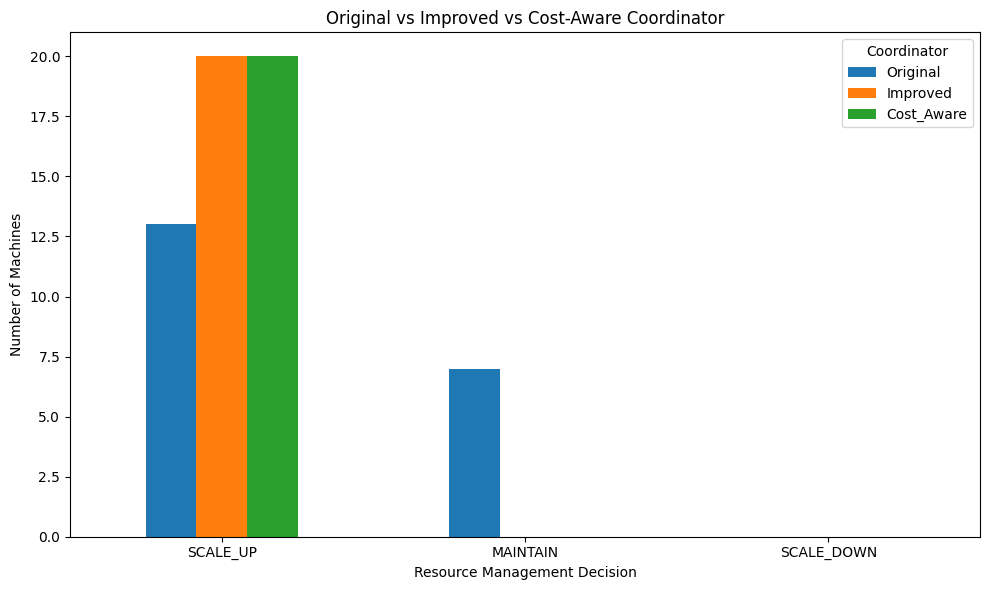

In [ ]:
import matplotlib.pyplot as plt

ax = final_coordinator_comparison.set_index(
    "Decision"
).plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Original vs Improved vs Cost-Aware Coordinator")
plt.xlabel("Resource Management Decision")
plt.ylabel("Number of Machines")
plt.xticks(rotation=0)
plt.legend(title="Coordinator")
plt.tight_layout()

plt.savefig(
    "/content/AgenticCloudManagement/results/graphs/"
    "final_coordinator_comparison.png",
    dpi=300
)

plt.show()

In [ ]:
threshold_experiments = [
    (70, 80),
    (80, 85),
    (90, 95)
]

sensitivity_results = []

for cpu_limit, memory_limit in threshold_experiments:

    decisions = comparison_df.apply(
        lambda row: (
            "SCALE_UP"
            if (
                row["current_cpu"] >= cpu_limit
                or row["current_memory"] >= memory_limit
                or row["predicted_cpu"] >= cpu_limit
                or row["predicted_memory"] >= memory_limit
            )
            else "MAINTAIN"
        ),
        axis=1
    )

    sensitivity_results.append({
        "CPU_Threshold": cpu_limit,
        "Memory_Threshold": memory_limit,
        "SCALE_UP": (decisions == "SCALE_UP").sum(),
        "MAINTAIN": (decisions == "MAINTAIN").sum()
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df)

sensitivity_df.to_csv(
    "/content/AgenticCloudManagement/results/tables/"
    "threshold_sensitivity_analysis.csv",
    index=False
)

,CPU_Threshold,Memory_Threshold,SCALE_UP,MAINTAIN
0,70,80,20,0
1,80,85,20,0
2,90,95,7,13


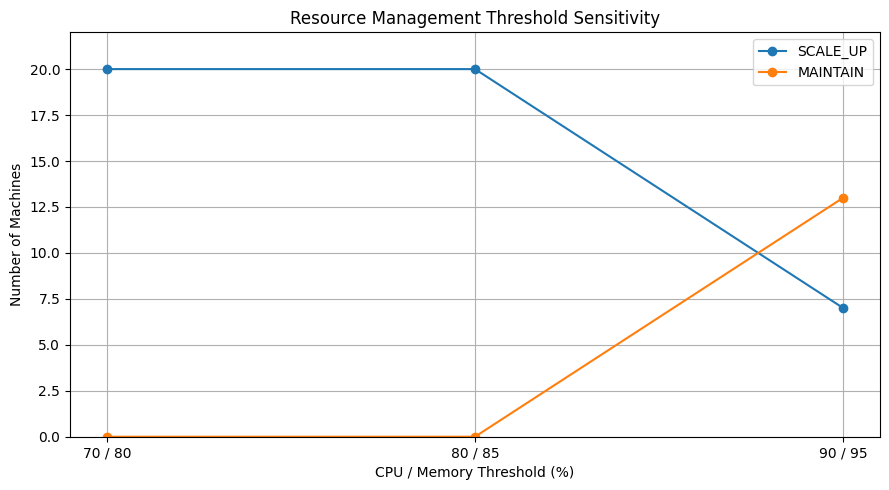

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

x_labels = ["70 / 80", "80 / 85", "90 / 95"]

plt.plot(
    x_labels,
    sensitivity_df["SCALE_UP"],
    marker="o",
    label="SCALE_UP"
)

plt.plot(
    x_labels,
    sensitivity_df["MAINTAIN"],
    marker="o",
    label="MAINTAIN"
)

plt.title("Resource Management Threshold Sensitivity")
plt.xlabel("CPU / Memory Threshold (%)")
plt.ylabel("Number of Machines")
plt.ylim(0, 22)
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/AgenticCloudManagement/results/graphs/"
    "threshold_sensitivity_analysis.png",
    dpi=300
)

plt.show()

final result table

In [ ]:
import pandas as pd

final_evaluation = pd.DataFrame([
    ["Dataset", "Alibaba Cluster Trace 2018"],
    ["Selected machines", 20],
    ["Selected usage records", 1290470],
    ["Forecasting dataset records", 1287817],
    ["Training samples", 1030246],
    ["Testing samples", 257571],
    ["Median forecasting interval", "10 seconds"],

    ["CPU Random Forest MAE", 3.7971],
    ["CPU Random Forest RMSE", 5.4380],
    ["CPU Persistence MAE", 3.8393],
    ["CPU Persistence RMSE", 5.6940],

    ["Memory Random Forest MAE", 0.5859],
    ["Memory Random Forest RMSE", 0.8467],
    ["Memory Persistence MAE", 0.5325],
    ["Memory Persistence RMSE", 0.8591],

    ["Original SCALE_UP decisions", 13],
    ["Original MAINTAIN decisions", 7],
    ["Improved SCALE_UP decisions", 20],
    ["Cost-aware SCALE_UP decisions", 20],

    ["Security resource-risk machines", 7],
    ["Cost-warning machines", 3],
    ["Machines with explanations", 20],
    ["Missing final decisions", 0],
    ["Missing explanations", 0],

    ["Estimated total cost per hour", 89.46],
    ["Average estimated cost per machine/hour", 4.473],

    ["Sensitivity: SCALE_UP at 70/80", 20],
    ["Sensitivity: SCALE_UP at 80/85", 20],
    ["Sensitivity: SCALE_UP at 90/95", 7]
], columns=["Metric", "Result"])

display(final_evaluation)

final_evaluation.to_csv(
    "/content/AgenticCloudManagement/results/tables/"
    "final_experimental_evaluation.csv",
    index=False
)

print("Final experimental evaluation saved successfully.")

,Metric,Result
0,Dataset,Alibaba Cluster Trace 2018
1,Selected machines,20
2,Selected usage records,1290470
3,Forecasting dataset records,1287817
4,Training samples,1030246
5,Testing samples,257571
6,Median forecasting interval,10 seconds
7,CPU Random Forest MAE,3.7971
8,CPU Random Forest RMSE,5.438
9,CPU Persistence MAE,3.8393


Final experimental evaluation saved successfully.
